# Home Loan Default Prediction

## 1. Project Introduction

### 1.1 Project Overview

In the banking and finance industry, providing loans to customers always involves some level of risk. One of the major challenges faced by financial institutions is identifying customers who may have difficulty repaying their loans.

In this project, I will analyze historical loan application data to understand customer financial backgrounds, previous credit history, and repayment patterns. Based on this analysis, I will develop machine learning models to predict the possibility of loan default.

The main aim is to understand the factors associated with loan defaults and help financial institutions make more informed lending decisions.

### 1.2 Problem Statement

The objective of this project is to analyze customer loan application data and develop a predictive model that can identify customers who are more likely to default on their loans.

To achieve this, I will explore the available data, identify important patterns, handle missing values, prepare the data for machine learning, and compare different classification models.

### 1.3 Project Objectives

- Understand the loan application data and its important features.
- Perform data cleaning and handle missing values.
- Explore customer information using statistical analysis and visualizations.
- Identify factors that may be associated with loan defaults.
- Build machine learning models to predict loan default.
- Compare model performance using different evaluation metrics.
- Analyze customer segments based on their predicted default risk.

### 1.4 Project Domain

**Banking and Finance**

### 1.5 Target Variable

The target variable in this project is `TARGET`.

It represents whether a customer has experienced loan payment difficulties.

- **0 – Non-defaulter:** Customer did not experience the defined payment difficulties.
- **1 – Defaulter:** Customer experienced the defined payment difficulties.

## 2. Business Understanding

### 2.1 Understanding the Business Problem

Banks and financial institutions provide loans to customers based on their financial information and repayment capacity. However, not every customer is able to repay their loan on time.

When customers fail to make their loan payments, banks may face financial losses. Therefore, it is important to understand the risk associated with each loan application.

In this project, I will use historical customer data to study loan repayment difficulties and identify patterns that may help predict future defaults.

### 2.2 Business Questions

During this project, I will try to answer the following questions:

1. How many customers are defaulters and non-defaulters?
2. Does customer income have any relationship with loan default?
3. Does the amount of credit affect the chances of default?
4. Which customer categories show higher default rates?
5. Does previous credit history provide useful information?
6. Which machine learning model performs better at identifying potential defaulters?

### 2.3 Expected Outcome

By the end of this project, I aim to:

- Understand the main factors associated with loan default.
- Find useful patterns in customer financial information.
- Develop models that can estimate the possibility of loan default.
- Compare different models and identify a suitable candidate for further evaluation.
- Provide useful insights that can support better risk assessment.

### 2.4 Business Impact

The analysis may help financial institutions better understand customer repayment risks, identify potentially high-risk applications, and improve their loan risk assessment process.

## 3. Dataset Description

### 3.1 About the Dataset

The dataset contains information about customers who applied for loans. It includes their personal details, financial information, previous credit records, and repayment history.

The project provides seven CSV files. Each file contains different types of customer and loan-related information.

### 3.2 Description of Individual Files

**1. application_train.csv**

This is the main dataset used for the project. It contains information about loan applications and includes the target variable `TARGET`, which indicates whether a customer experienced payment difficulties.

Each row represents one loan application.

**2. bureau.csv**

This file contains information about customers' previous loans from other financial institutions, as reported to the Credit Bureau.

It helps us understand the customer's previous credit history.

**3. bureau_balance.csv**

This file contains monthly balance information for previous credits reported to the Credit Bureau.

It provides details about how customers' previous credit accounts changed over time.

**4. POS_CASH_balance.csv**

This file contains monthly records of customers' previous POS and cash loans with Home Credit.

It helps us understand the status of their previous loans.

**5. credit_card_balance.csv**

This file contains monthly balance information about customers' previous credit cards with Home Credit.

It provides information about their credit card usage and outstanding balances.

**6. previous_application.csv**

This file contains information about customers' previous loan applications submitted to Home Credit.

It helps us understand their earlier loan application history.

**7. installments_payments.csv**

This file contains repayment information for previously disbursed loans.

It includes records of payments made by customers as well as missed payments.

### 3.3 Understanding the Dataset Structure

All seven files contain different types of information about customers and their loan history.

The `application_train.csv` file will be our main dataset because it contains the target variable required for prediction.

The remaining files provide additional information that may help us understand customer credit behaviour and improve our predictive model.

For this submission, I used only application_train.csv for modelling. The other six files are listed as future work in the Limitations section.

### 3.4 Dataset Summary

| File Name | Main Information |
|---|---|
| application_train.csv | Loan application details |
| bureau.csv | Previous external credit records |
| bureau_balance.csv | Monthly credit balance history |
| POS_CASH_balance.csv | Previous POS and cash loan records |
| credit_card_balance.csv | Credit card balance history |
| previous_application.csv | Previous loan applications |
| installments_payments.csv | Loan repayment history |

## 4. Importing Libraries

In this project, I will use Python libraries to perform data analysis, create visualizations, and build machine learning models.

Each library has a different purpose. I will import only the libraries required for the project.

In [1]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

import os
import warnings

warnings.filterwarnings('ignore')

## 5. Data Loading

In this section, I will load the main application dataset using the Pandas library.

The `application_train.csv` file contains customer information, financial details, and the target variable required for predicting loan defaults.

I will start with this dataset and explore its structure before moving to data cleaning and analysis.

In [2]:
df = pd.read_csv("data/application_train.csv")

In [3]:
df.head()

,SK_ID_CURR,TARGET,NAME_CONTRACT_TYPE,CODE_GENDER,FLAG_OWN_CAR,FLAG_OWN_REALTY,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,...,FLAG_DOCUMENT_18,FLAG_DOCUMENT_19,FLAG_DOCUMENT_20,FLAG_DOCUMENT_21,AMT_REQ_CREDIT_BUREAU_HOUR,AMT_REQ_CREDIT_BUREAU_DAY,AMT_REQ_CREDIT_BUREAU_WEEK,AMT_REQ_CREDIT_BUREAU_MON,AMT_REQ_CREDIT_BUREAU_QRT,AMT_REQ_CREDIT_BUREAU_YEAR
0,100002,1,Cash loans,M,N,Y,0,202500.0,406597.5,24700.5,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,1.0
1,100003,0,Cash loans,F,N,N,0,270000.0,1293502.5,35698.5,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0
2,100004,0,Revolving loans,M,Y,Y,0,67500.0,135000.0,6750.0,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0
3,100006,0,Cash loans,F,N,Y,0,135000.0,312682.5,29686.5,...,0,0,0,0,NaN,NaN,NaN,NaN,NaN,NaN
4,100007,0,Cash loans,M,N,Y,0,121500.0,513000.0,21865.5,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0


## 6. Data Understanding

After loading the dataset, I will explore its structure to understand the information available.

In this section, I will check the number of rows and columns, column names, data types, and a few sample records.

This will help me understand the dataset before starting the cleaning and analysis process.

In [4]:
df.head()

,SK_ID_CURR,TARGET,NAME_CONTRACT_TYPE,CODE_GENDER,FLAG_OWN_CAR,FLAG_OWN_REALTY,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,...,FLAG_DOCUMENT_18,FLAG_DOCUMENT_19,FLAG_DOCUMENT_20,FLAG_DOCUMENT_21,AMT_REQ_CREDIT_BUREAU_HOUR,AMT_REQ_CREDIT_BUREAU_DAY,AMT_REQ_CREDIT_BUREAU_WEEK,AMT_REQ_CREDIT_BUREAU_MON,AMT_REQ_CREDIT_BUREAU_QRT,AMT_REQ_CREDIT_BUREAU_YEAR
0,100002,1,Cash loans,M,N,Y,0,202500.0,406597.5,24700.5,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,1.0
1,100003,0,Cash loans,F,N,N,0,270000.0,1293502.5,35698.5,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0
2,100004,0,Revolving loans,M,Y,Y,0,67500.0,135000.0,6750.0,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0
3,100006,0,Cash loans,F,N,Y,0,135000.0,312682.5,29686.5,...,0,0,0,0,NaN,NaN,NaN,NaN,NaN,NaN
4,100007,0,Cash loans,M,N,Y,0,121500.0,513000.0,21865.5,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0


In [5]:
df.tail()

,SK_ID_CURR,TARGET,NAME_CONTRACT_TYPE,CODE_GENDER,FLAG_OWN_CAR,FLAG_OWN_REALTY,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,...,FLAG_DOCUMENT_18,FLAG_DOCUMENT_19,FLAG_DOCUMENT_20,FLAG_DOCUMENT_21,AMT_REQ_CREDIT_BUREAU_HOUR,AMT_REQ_CREDIT_BUREAU_DAY,AMT_REQ_CREDIT_BUREAU_WEEK,AMT_REQ_CREDIT_BUREAU_MON,AMT_REQ_CREDIT_BUREAU_QRT,AMT_REQ_CREDIT_BUREAU_YEAR
307506,456251,0,Cash loans,M,N,N,0,157500.0,254700.0,27558.0,...,0,0,0,0,NaN,NaN,NaN,NaN,NaN,NaN
307507,456252,0,Cash loans,F,N,Y,0,72000.0,269550.0,12001.5,...,0,0,0,0,NaN,NaN,NaN,NaN,NaN,NaN
307508,456253,0,Cash loans,F,N,Y,0,153000.0,677664.0,29979.0,...,0,0,0,0,1.0,0.0,0.0,1.0,0.0,1.0
307509,456254,1,Cash loans,F,N,Y,0,171000.0,370107.0,20205.0,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0
307510,456255,0,Cash loans,F,N,N,0,157500.0,675000.0,49117.5,...,0,0,0,0,0.0,0.0,0.0,2.0,0.0,1.0


In [6]:
df.shape

(307511, 122)

In [7]:
df.columns.to_list()

['SK_ID_CURR',
 'TARGET',
 'NAME_CONTRACT_TYPE',
 'CODE_GENDER',
 'FLAG_OWN_CAR',
 'FLAG_OWN_REALTY',
 'CNT_CHILDREN',
 'AMT_INCOME_TOTAL',
 'AMT_CREDIT',
 'AMT_ANNUITY',
 'AMT_GOODS_PRICE',
 'NAME_TYPE_SUITE',
 'NAME_INCOME_TYPE',
 'NAME_EDUCATION_TYPE',
 'NAME_FAMILY_STATUS',
 'NAME_HOUSING_TYPE',
 'REGION_POPULATION_RELATIVE',
 'DAYS_BIRTH',
 'DAYS_EMPLOYED',
 'DAYS_REGISTRATION',
 'DAYS_ID_PUBLISH',
 'OWN_CAR_AGE',
 'FLAG_MOBIL',
 'FLAG_EMP_PHONE',
 'FLAG_WORK_PHONE',
 'FLAG_CONT_MOBILE',
 'FLAG_PHONE',
 'FLAG_EMAIL',
 'OCCUPATION_TYPE',
 'CNT_FAM_MEMBERS',
 'REGION_RATING_CLIENT',
 'REGION_RATING_CLIENT_W_CITY',
 'WEEKDAY_APPR_PROCESS_START',
 'HOUR_APPR_PROCESS_START',
 'REG_REGION_NOT_LIVE_REGION',
 'REG_REGION_NOT_WORK_REGION',
 'LIVE_REGION_NOT_WORK_REGION',
 'REG_CITY_NOT_LIVE_CITY',
 'REG_CITY_NOT_WORK_CITY',
 'LIVE_CITY_NOT_WORK_CITY',
 'ORGANIZATION_TYPE',
 'EXT_SOURCE_1',
 'EXT_SOURCE_2',
 'EXT_SOURCE_3',
 'APARTMENTS_AVG',
 'BASEMENTAREA_AVG',
 'YEARS_BEGINEXPLUATATION_A

In [8]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 307511 entries, 0 to 307510
Columns: 122 entries, SK_ID_CURR to AMT_REQ_CREDIT_BUREAU_YEAR
dtypes: float64(65), int64(41), object(16)
memory usage: 286.2+ MB


In [9]:
df.describe()

,SK_ID_CURR,TARGET,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,AMT_GOODS_PRICE,REGION_POPULATION_RELATIVE,DAYS_BIRTH,DAYS_EMPLOYED,...,FLAG_DOCUMENT_18,FLAG_DOCUMENT_19,FLAG_DOCUMENT_20,FLAG_DOCUMENT_21,AMT_REQ_CREDIT_BUREAU_HOUR,AMT_REQ_CREDIT_BUREAU_DAY,AMT_REQ_CREDIT_BUREAU_WEEK,AMT_REQ_CREDIT_BUREAU_MON,AMT_REQ_CREDIT_BUREAU_QRT,AMT_REQ_CREDIT_BUREAU_YEAR
count,307511.000000,307511.000000,307511.000000,3.075110e+05,3.075110e+05,307499.000000,3.072330e+05,307511.000000,307511.000000,307511.000000,...,307511.000000,307511.000000,307511.000000,307511.000000,265992.000000,265992.000000,265992.000000,265992.000000,265992.000000,265992.000000
mean,278180.518577,0.080729,0.417052,1.687979e+05,5.990260e+05,27108.573909,5.383962e+05,0.020868,-16036.995067,63815.045904,...,0.008130,0.000595,0.000507,0.000335,0.006402,0.007000,0.034362,0.267395,0.265474,1.899974
std,102790.175348,0.272419,0.722121,2.371231e+05,4.024908e+05,14493.737315,3.694465e+05,0.013831,4363.988632,141275.766519,...,0.089798,0.024387,0.022518,0.018299,0.083849,0.110757,0.204685,0.916002,0.794056,1.869295
min,100002.000000,0.000000,0.000000,2.565000e+04,4.500000e+04,1615.500000,4.050000e+04,0.000290,-25229.000000,-17912.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,189145.500000,0.000000,0.000000,1.125000e+05,2.700000e+05,16524.000000,2.385000e+05,0.010006,-19682.000000,-2760.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,278202.000000,0.000000,0.000000,1.471500e+05,5.135310e+05,24903.000000,4.500000e+05,0.018850,-15750.000000,-1213.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000
75%,367142.500000,0.000000,1.000000,2.025000e+05,8.086500e+05,34596.000000,6.795000e+05,0.028663,-12413.000000,-289.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,3.000000
max,456255.000000,1.000000,19.000000,1.170000e+08,4.050000e+06,258025.500000,4.050000e+06,0.072508,-7489.000000,365243.000000,...,1.000000,1.000000,1.000000,1.000000,4.000000,9.000000,8.000000,27.000000,261.000000,25.000000


In [10]:
df.describe(include="object")

,NAME_CONTRACT_TYPE,CODE_GENDER,FLAG_OWN_CAR,FLAG_OWN_REALTY,NAME_TYPE_SUITE,NAME_INCOME_TYPE,NAME_EDUCATION_TYPE,NAME_FAMILY_STATUS,NAME_HOUSING_TYPE,OCCUPATION_TYPE,WEEKDAY_APPR_PROCESS_START,ORGANIZATION_TYPE,FONDKAPREMONT_MODE,HOUSETYPE_MODE,WALLSMATERIAL_MODE,EMERGENCYSTATE_MODE
count,307511,307511,307511,307511,306219,307511,307511,307511,307511,211120,307511,307511,97216,153214,151170,161756
unique,2,3,2,2,7,8,5,6,6,18,7,58,4,3,7,2
top,Cash loans,F,N,Y,Unaccompanied,Working,Secondary / secondary special,Married,House / apartment,Laborers,TUESDAY,Business Entity Type 3,reg oper account,block of flats,Panel,No
freq,278232,202448,202924,213312,248526,158774,218391,196432,272868,55186,53901,67992,73830,150503,66040,159428


### 6.1 Initial Dataset Observations

After exploring the dataset, I found the following:

- The dataset contains **307,511 loan application records** and **122 columns**.
- It contains **65 float columns, 41 integer columns, and 16 categorical columns**.
- The dataset uses approximately **286.2 MB of memory**.
- The dataset includes customer details such as income, education, occupation, family status, housing, and loan information.
- Some numerical and categorical columns contain missing values.
- The `OCCUPATION_TYPE` column has a large number of missing values.
- The `ORGANIZATION_TYPE` column contains 58 unique categories.
- The most common contract type is `Cash loans`.
- The most common family status is `Married`.

Overall, the dataset contains useful customer and financial information. However, some columns have missing values, which I will check and handle during the data cleaning process.

## 7. Data Cleaning

In this section, I will clean the dataset before using it for analysis and model building.

I will check and handle missing values, remove unnecessary columns if required, and prepare the data for further analysis.

### 7.1 Creating a Copy of the Dataset

First, I will create a copy of the original dataset. This will help me keep the original data safe while making changes to the copied dataset.

In [11]:
df_clean = df.copy()

In [12]:
df_clean.shape

(307511, 122)

### 7.2 Checking Missing Values

Now, I will check the missing values in the copied dataset. This will help me identify which columns need cleaning and how much data is missing from each column.

In [13]:
missing_values = df_clean.isnull().sum()

missing_values = missing_values[missing_values > 0].sort_values(ascending=False) 

missing_values.head(20)

COMMONAREA_MEDI             214865
COMMONAREA_AVG              214865
COMMONAREA_MODE             214865
NONLIVINGAPARTMENTS_MEDI    213514
NONLIVINGAPARTMENTS_MODE    213514
NONLIVINGAPARTMENTS_AVG     213514
FONDKAPREMONT_MODE          210295
LIVINGAPARTMENTS_MODE       210199
LIVINGAPARTMENTS_MEDI       210199
LIVINGAPARTMENTS_AVG        210199
FLOORSMIN_MODE              208642
FLOORSMIN_MEDI              208642
FLOORSMIN_AVG               208642
YEARS_BUILD_MODE            204488
YEARS_BUILD_MEDI            204488
YEARS_BUILD_AVG             204488
OWN_CAR_AGE                 202929
LANDAREA_AVG                182590
LANDAREA_MEDI               182590
LANDAREA_MODE               182590
dtype: int64

### 7.3 Calculating Missing Value Percentage

The number of missing values alone does not tell us how much data is missing from a column.

So, I will calculate the missing value percentage for each column. This will help me decide which columns need special attention during cleaning.

In [14]:
missing_percentage = (df_clean.isnull().sum() / len(df_clean)) * 100

missing_percentage = missing_percentage[missing_percentage > 0].sort_values(ascending=False) 

missing_percentage.head(20)

COMMONAREA_MEDI             69.872297
COMMONAREA_AVG              69.872297
COMMONAREA_MODE             69.872297
NONLIVINGAPARTMENTS_MEDI    69.432963
NONLIVINGAPARTMENTS_MODE    69.432963
NONLIVINGAPARTMENTS_AVG     69.432963
FONDKAPREMONT_MODE          68.386172
LIVINGAPARTMENTS_MODE       68.354953
LIVINGAPARTMENTS_MEDI       68.354953
LIVINGAPARTMENTS_AVG        68.354953
FLOORSMIN_MODE              67.848630
FLOORSMIN_MEDI              67.848630
FLOORSMIN_AVG               67.848630
YEARS_BUILD_MODE            66.497784
YEARS_BUILD_MEDI            66.497784
YEARS_BUILD_AVG             66.497784
OWN_CAR_AGE                 65.990810
LANDAREA_AVG                59.376738
LANDAREA_MEDI               59.376738
LANDAREA_MODE               59.376738
dtype: float64

### 7.4 Identifying Columns with High Missing Values

After calculating the missing value percentage, I found that some columns have more than 60% missing data.

These columns may not provide enough information for our analysis. I will identify them first and review how many columns are affected before deciding whether to remove them.

In [15]:
columns_to_drop = missing_percentage[missing_percentage > 60].index

print("Number of columns with more than 60% missing values:", len(columns_to_drop))

print("\nColumns identified:")
print(columns_to_drop.tolist())

Number of columns with more than 60% missing values: 17

Columns identified:
['COMMONAREA_MEDI', 'COMMONAREA_AVG', 'COMMONAREA_MODE', 'NONLIVINGAPARTMENTS_MEDI', 'NONLIVINGAPARTMENTS_MODE', 'NONLIVINGAPARTMENTS_AVG', 'FONDKAPREMONT_MODE', 'LIVINGAPARTMENTS_MODE', 'LIVINGAPARTMENTS_MEDI', 'LIVINGAPARTMENTS_AVG', 'FLOORSMIN_MODE', 'FLOORSMIN_MEDI', 'FLOORSMIN_AVG', 'YEARS_BUILD_MODE', 'YEARS_BUILD_MEDI', 'YEARS_BUILD_AVG', 'OWN_CAR_AGE']


### 7.5 Removing Columns with High Missing Values

After reviewing the missing value percentages, I decided to use 60% as the threshold.

I found 17 columns with more than 60% missing values. I will remove these columns because they contain a large amount of missing information.

I will keep the remaining columns for further analysis and preprocessing.

In [16]:
df_clean.drop(columns=columns_to_drop, inplace=True)

In [17]:
df_clean.shape

(307511, 105)

### 7.6 Checking Remaining Missing Values

After removing columns with more than 60% missing values, I will check the remaining missing values.

This will help me identify which columns still need attention before moving to data preprocessing.

In [18]:
remaining_missing = df_clean.isnull().sum()

remaining_missing = remaining_missing[remaining_missing > 0].sort_values(ascending=False)

remaining_missing.head(20)

LANDAREA_AVG          182590
LANDAREA_MEDI         182590
LANDAREA_MODE         182590
BASEMENTAREA_MODE     179943
BASEMENTAREA_AVG      179943
BASEMENTAREA_MEDI     179943
EXT_SOURCE_1          173378
NONLIVINGAREA_MODE    169682
NONLIVINGAREA_AVG     169682
NONLIVINGAREA_MEDI    169682
ELEVATORS_MEDI        163891
ELEVATORS_AVG         163891
ELEVATORS_MODE        163891
WALLSMATERIAL_MODE    156341
APARTMENTS_MEDI       156061
APARTMENTS_MODE       156061
APARTMENTS_AVG        156061
ENTRANCES_MEDI        154828
ENTRANCES_MODE        154828
ENTRANCES_AVG         154828
dtype: int64

### 7.7 Identifying Numerical and Categorical Columns

The dataset contains both numerical and categorical information.

Numerical columns contain values such as income, loan amount, and age. Categorical columns contain information such as gender, education, and occupation.

I will separate these columns because missing values need to be handled differently for numerical and categorical data.

In [19]:
numerical_columns = df_clean.select_dtypes(include="number").columns
categorical_columns = df_clean.select_dtypes(include= "object").columns

print("Numerical columns:", len(numerical_columns))
print("Categorical columns:", len(categorical_columns))

Numerical columns: 90
Categorical columns: 15


### 7.8 Handling Missing Values

After identifying numerical and categorical columns, I will fill the remaining missing values.

For numerical columns, I will use the median because it is less affected by extreme values.

For categorical columns, I will use the mode because it represents the most common category.

This will help prepare the dataset for further analysis and model building.

In [20]:
# Fill missing numerical values with median 
for col in numerical_columns: 
    df_clean[col] = df_clean[col].fillna(df_clean[col].median())

# Fill missing categorical values with mode 
for col in categorical_columns: 
    df_clean[col] = df_clean[col].fillna(df_clean[col].mode()[0])

### 7.9 Verifying Missing Values

After filling the missing values, I will check the dataset again to make sure no missing values remain.

This will help me confirm that the cleaning process was successful.

In [21]:
print("Total missing values:", df_clean.isnull().sum().sum())

Total missing values: 0


### 7.10 Final Duplicate Check

After completing the data cleaning process, I will check for duplicate records once again.

This will help me confirm that the cleaned dataset does not contain any duplicate rows.

In [22]:
df_clean.duplicated().sum()

np.int64(0)

### 7.11 Handling Unusual Values in DAYS_EMPLOYED

While checking the employment information, I found that the `DAYS_EMPLOYED` column contains an unusual value of 365243.

This value does not represent a realistic employment duration. I will replace it with a missing value so that it does not affect further calculations.

In [23]:
df_clean['DAYS_EMPLOYED'] = df_clean['DAYS_EMPLOYED'].replace(365243, np.nan)

df_clean['DAYS_EMPLOYED'].isnull().sum()

np.int64(55374)

### 7.12 Filling Missing Values in DAYS_EMPLOYED

After replacing the unusual value with missing values, I will fill the missing values in the `DAYS_EMPLOYED` column using the median.

I am using the median because it is less affected by extreme values.

In [24]:
df_clean['DAYS_EMPLOYED'] = df_clean['DAYS_EMPLOYED'].fillna(
    df_clean['DAYS_EMPLOYED'].median()
)

df_clean['DAYS_EMPLOYED'].isnull().sum()

np.int64(0)

### 7.13 Converting Days into Years

The `DAYS_BIRTH` and `DAYS_EMPLOYED` columns contain negative values. I will convert these values into years to make them easier to understand and use during analysis.

In [25]:
df_clean['AGE'] = (-df_clean['DAYS_BIRTH'] / 365).astype(int)

df_clean['YEARS_EMPLOYED'] = (
    -df_clean['DAYS_EMPLOYED'] / 365
).round(1)

df_clean[['DAYS_BIRTH', 'AGE', 'DAYS_EMPLOYED', 'YEARS_EMPLOYED']].head()

,DAYS_BIRTH,AGE,DAYS_EMPLOYED,YEARS_EMPLOYED
0,-9461,25,-637.0,1.7
1,-16765,45,-1188.0,3.3
2,-19046,52,-225.0,0.6
3,-19005,52,-3039.0,8.3
4,-19932,54,-3038.0,8.3


### 7.14 Handling XNA Values

Some categorical columns contain `XNA` values. I will check these values and handle them appropriately to improve data quality.

In [26]:
print("CODE_GENDER:")
print(df_clean['CODE_GENDER'].value_counts())

print("\nORGANIZATION_TYPE:")
print(df_clean['ORGANIZATION_TYPE'].value_counts().head(10))

print("\nXNA counts:")
print("CODE_GENDER:", (df_clean['CODE_GENDER'] == 'XNA').sum())
print("ORGANIZATION_TYPE:", (df_clean['ORGANIZATION_TYPE'] == 'XNA').sum())

CODE_GENDER:
CODE_GENDER
F      202448
M      105059
XNA         4
Name: count, dtype: int64

ORGANIZATION_TYPE:
ORGANIZATION_TYPE
Business Entity Type 3    67992
XNA                       55374
Self-employed             38412
Other                     16683
Medicine                  11193
Business Entity Type 2    10553
Government                10404
School                     8893
Trade: type 7              7831
Kindergarten               6880
Name: count, dtype: int64

XNA counts:
CODE_GENDER: 4
ORGANIZATION_TYPE: 55374


### 7.15 Handling XNA Values

The `CODE_GENDER` column contains only 4 XNA values, so I will replace them with the most common value.

The `ORGANIZATION_TYPE` column contains 55,374 XNA values. I will replace them with `Unknown` to preserve the information that the organization type is unavailable.

In [27]:
gender_mode =df_clean['CODE_GENDER'].mode()[0]

df_clean['CODE_GENDER'] = df_clean['CODE_GENDER'].replace('XNA', gender_mode)

df_clean['ORGANIZATION_TYPE'] = df_clean['ORGANIZATION_TYPE'].replace('XNA', 'Unknown')

print("Code_gender XNA:", df_clean['CODE_GENDER'].value_counts())
print("Organization_type XNA:", (df_clean["ORGANIZATION_TYPE"] == 'XNA').sum())

Code_gender XNA: CODE_GENDER
F    202452
M    105059
Name: count, dtype: int64
Organization_type XNA: 0


### 7.16 Checking Outliers in Financial Amount Columns

I will check the financial amount columns to identify unusually high or low values.

The columns include customer income, credit amount, annuity amount, and goods price.

I will use statistical summaries and the IQR method to identify outliers. I will not remove any values without a valid reason.

In [28]:
amount_columns = [
    'AMT_INCOME_TOTAL', 
    'AMT_CREDIT', 
    'AMT_ANNUITY', 
    'AMT_GOODS_PRICE'
]
df_clean[amount_columns].describe()

,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,AMT_GOODS_PRICE
count,3.075110e+05,3.075110e+05,307511.000000,3.075110e+05
mean,1.687979e+05,5.990260e+05,27108.487841,5.383163e+05
std,2.371231e+05,4.024908e+05,14493.461065,3.692890e+05
min,2.565000e+04,4.500000e+04,1615.500000,4.050000e+04
25%,1.125000e+05,2.700000e+05,16524.000000,2.385000e+05
50%,1.471500e+05,5.135310e+05,24903.000000,4.500000e+05
75%,2.025000e+05,8.086500e+05,34596.000000,6.795000e+05
max,1.170000e+08,4.050000e+06,258025.500000,4.050000e+06


### 7.17Identifying Outliers Using IQR

I will use the Interquartile Range (IQR) method to identify outliers in all four financial columns.

I will calculate the lower and upper limits and count the values outside these limits. I will keep the original values for now.

In [29]:
for col in amount_columns: 
    Q1 = df_clean[col].quantile(0.25)
    Q3 = df_clean[col].quantile(0.75)

    IQR = Q3 - Q1 

    lower_limit = Q1 - 1.5 * IQR 
    upper_limit = Q3 + 1.5 * IQR 

    outlier_count = (
        (df_clean[col] < lower_limit) | 
        (df_clean[col] > upper_limit)
    ).sum()

    print(f"\nColumn: {col}")
    print("Lower Limit:", lower_limit) 
    print("Upper Limit:", upper_limit)
    print("Outliers:", outlier_count)


Column: AMT_INCOME_TOTAL
Lower Limit: -22500.0
Upper Limit: 337500.0
Outliers: 14035

Column: AMT_CREDIT
Lower Limit: -537975.0
Upper Limit: 1616625.0
Outliers: 6562

Column: AMT_ANNUITY
Lower Limit: -10584.0
Upper Limit: 61704.0
Outliers: 7504

Column: AMT_GOODS_PRICE
Lower Limit: -423000.0
Upper Limit: 1341000.0
Outliers: 14728


### Financial Columns – Final Observation

I checked four financial columns for negative values and outliers.

There were no negative values in these columns. However, the IQR method identified some extreme values.

I decided to keep these values because they may represent genuine customer financial information. No records were removed or capped.

In [30]:
df_clean.dtypes.value_counts()

float64    51
int64      41
object     15
Name: count, dtype: int64

In [31]:
df_clean[['TARGET', 'AGE', 'YEARS_EMPLOYED',
          'CODE_GENDER', 'ORGANIZATION_TYPE']].dtypes

TARGET                 int64
AGE                    int64
YEARS_EMPLOYED       float64
CODE_GENDER           object
ORGANIZATION_TYPE     object
dtype: object

### Data Type Verification

I checked the data types of the important columns.

The target column and numerical columns have numeric data types, while categorical columns have object data types.

No data type conversion was required.

In [32]:
print("Final Dataset Shape:", df_clean.shape)
print("Total Missing Values:", df_clean.isnull().sum().sum())
print("Total Duplicate Rows:", df_clean.duplicated().sum())

Final Dataset Shape: (307511, 107)
Total Missing Values: 0
Total Duplicate Rows: 0


### 7.18 Final Data Cleaning Summary

In this section, I completed the main data cleaning steps.

- Created a working copy of the original dataset.
- Checked and handled missing values.
- Removed columns with more than 60% missing values.
- Filled missing numerical and categorical values.
- Handled the unusual value in `DAYS_EMPLOYED`.
- Created `AGE` and `YEARS_EMPLOYED` columns.
- Handled unknown `XNA` values.
- Checked financial columns for negative values and outliers.
- Verified the data types.
- Checked duplicate records.

After cleaning, the dataset contains 307,511 rows and 107 columns, with zero missing values and zero duplicate rows.

The cleaned dataset is now ready for exploratory data analysis.

## 8. Exploratory Data Analysis (EDA)

In this section, I will explore the cleaned dataset to understand customer information and identify patterns related to loan payment difficulties.

### 8.1 Target Variable Analysis

The `TARGET` column is our prediction variable.

- 0 represents customers who did not have payment difficulties.
- 1 represents customers who had payment difficulties.

I will visualize the distribution to understand the number of customers in each category.

TARGET
0    91.927118
1     8.072882
Name: proportion, dtype: float64


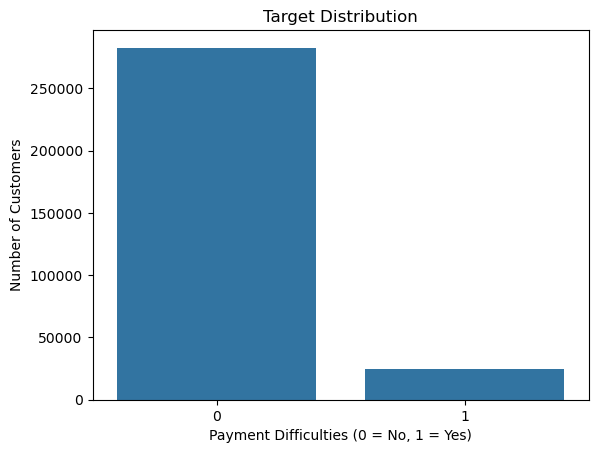

In [33]:
print(df['TARGET'].value_counts(normalize=True) * 100)

sns.countplot(x= 'TARGET', data= df_clean)
plt.title("Target Distribution")
plt.xlabel("Payment Difficulties (0 = No, 1 = Yes)")
plt.ylabel("Number of Customers")
plt.show()

#### 8.1 Observation

After analyzing the target variable, I found that:

- Approximately 91.93% of customers did not face payment difficulties.
- Approximately 8.07% of customers faced payment difficulties.
- The dataset is highly imbalanced because the number of customers in both categories is not equal.

This imbalance is important because our model should identify customers who may face payment difficulties, rather than simply predicting the majority class.

### 8.2 Customer Age Distribution

I will analyze the `AGE` column to understand the age distribution of loan applicants.

A histogram will help identify the most common customer age groups.

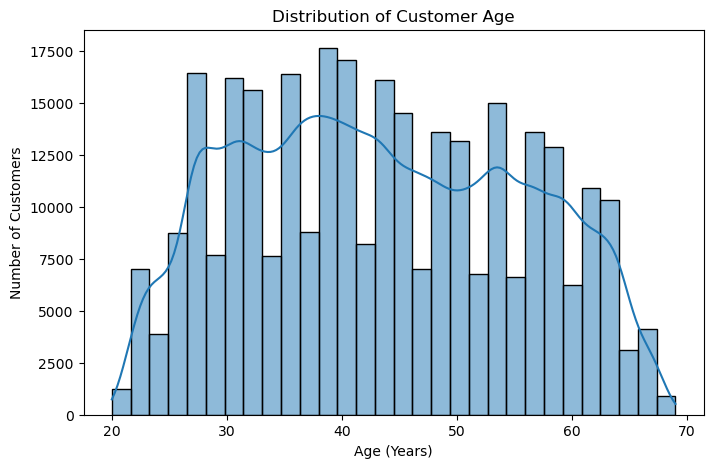

In [34]:
plt.figure(figsize= (8, 5))

sns.histplot(data=df_clean, x= 'AGE', bins=30, kde=True)
plt.title("Distribution of Customer Age")
plt.xlabel("Age (Years)")
plt.ylabel("Number of Customers")
plt.show()

#### 8.2 Observation – Customer Age Distribution

After analyzing the age distribution, I found that:

- Most loan applicants are between 25 and 60 years old.
- The highest concentration of customers is around 38–40 years.
- The number of applicants decreases in the older age groups.
- The dataset contains customers from approximately 20 to 69 years old.

This shows that most loan applicants belong to the middle-age groups.

### 8.3 Income Distribution

I will analyze the `AMT_INCOME_TOTAL` column to understand the income distribution of loan applicants.

A histogram will help visualize the distribution of customer income.

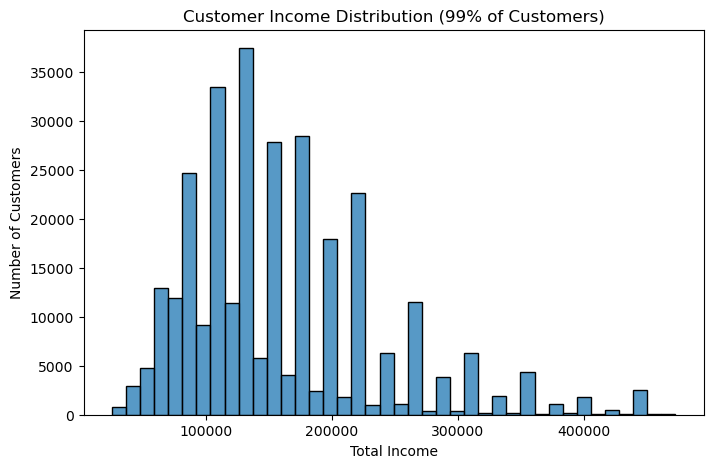

In [35]:
upper_limit = df_clean['AMT_INCOME_TOTAL'].quantile(0.99)

plt.figure(figsize=(8, 5))

sns.histplot(
    data=df_clean[df_clean['AMT_INCOME_TOTAL'] <= upper_limit],
    x='AMT_INCOME_TOTAL',
    bins=40
)

plt.title('Customer Income Distribution (99% of Customers)')
plt.xlabel('Total Income')
plt.ylabel('Number of Customers')

plt.show()

#### 8.3 Observation – Income Distribution

After analyzing the income distribution, I found that:

- Most customers have an income between 75,000 and 225,000.
- The highest concentration of customers is around 125,000–150,000.
- The number of customers decreases as income increases.
- A small number of customers have very high incomes.
- The distribution is positively skewed (right-skewed).

This shows that most loan applicants belong to the lower and middle-income groups, while fewer applicants have very high incomes.

### 8.4 Gender Distribution

I will analyze the `CODE_GENDER` column to understand the distribution of male and female loan applicants.

A count plot will help compare the number of applicants in each gender category.

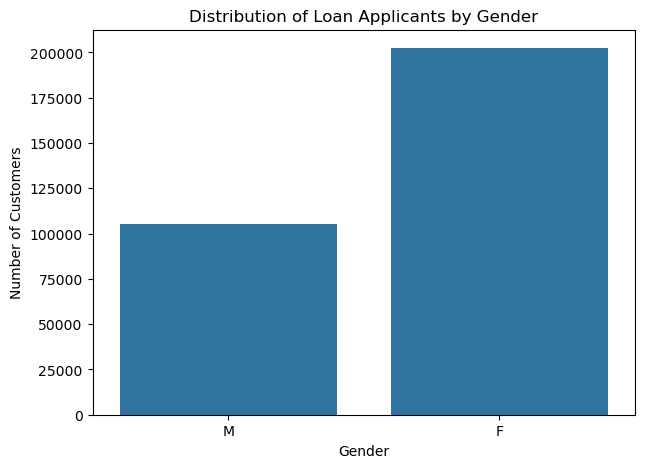

In [36]:
plt.figure(figsize=(7, 5))

sns.countplot(data=df_clean, x='CODE_GENDER')

plt.title('Distribution of Loan Applicants by Gender')
plt.xlabel('Gender')
plt.ylabel('Number of Customers')

plt.show()

**Observation:**
- The dataset has two gender categories: Female (F) and Male (M).
- Female applicants form the larger group, with about 66% of all customers.
- Male applicants make up about 34% of all customers.
- The two groups are not equal in size, so I will be careful when comparing them later.
- This chart only shows who applied. It does not show which group faces more payment difficulties. I will check that later by comparing gender with TARGET.

### 8.5 Education Distribution

I will analyze the `NAME_EDUCATION_TYPE` column to understand the education level of loan applicants.

A horizontal count plot will help compare the number of customers in each education category. I am using a horizontal plot because the category names are long.

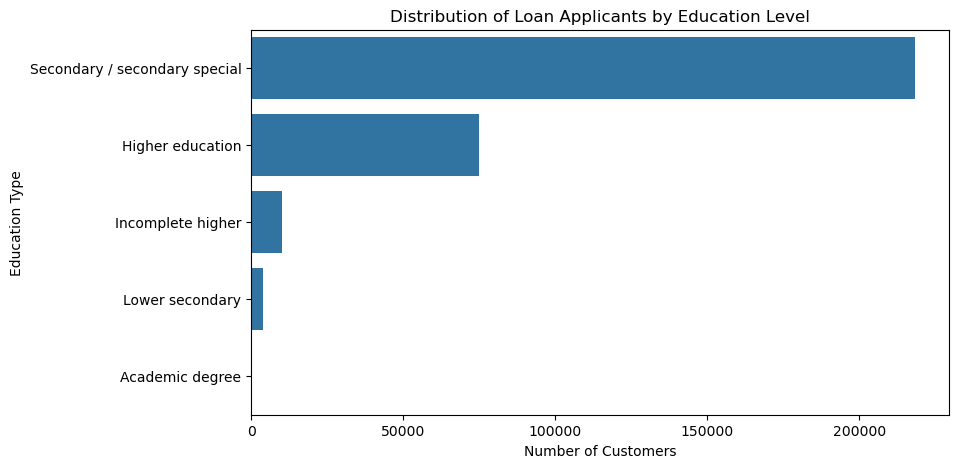

In [37]:
plt.figure(figsize=(9, 5))

sns.countplot(
    data=df_clean,
    y='NAME_EDUCATION_TYPE',
    order=df_clean['NAME_EDUCATION_TYPE'].value_counts(normalize=True).index    
)

plt.title('Distribution of Loan Applicants by Education Level')
plt.xlabel('Number of Customers')
plt.ylabel('Education Type')

plt.show()

**Observation:**
- The dataset has 5 education categories.
- Secondary / secondary special is the largest group, with about 71% of all customers.
- Higher education is the second largest group, with about 24%.
- Incomplete higher and Lower secondary are small groups, each with only a few percent of customers.
- Academic degree has very few customers, so its bar is almost not visible in the chart.
- Since the groups differ a lot in size, comparing raw counts would be misleading. In the next step, I will compare the payment difficulty rate for each education group instead.

### 8.6 Education vs TARGET

In the previous step, I saw that the education groups are very different in size. So instead of comparing raw counts, I will calculate the percentage of customers with payment difficulties (TARGET = 1) in each education group.

Since TARGET is 0 or 1, the average of TARGET for a group gives the payment difficulty rate for that group. I will also draw the overall average (about 8.07%) as a reference line.

In [38]:
education_rate = (
    df_clean.groupby('NAME_EDUCATION_TYPE')['TARGET']
    .mean()
    .mul(100)
    .sort_values(ascending=False)
)

print(education_rate.round(2))

NAME_EDUCATION_TYPE
Lower secondary                  10.93
Secondary / secondary special     8.94
Incomplete higher                 8.48
Higher education                  5.36
Academic degree                   1.83
Name: TARGET, dtype: float64


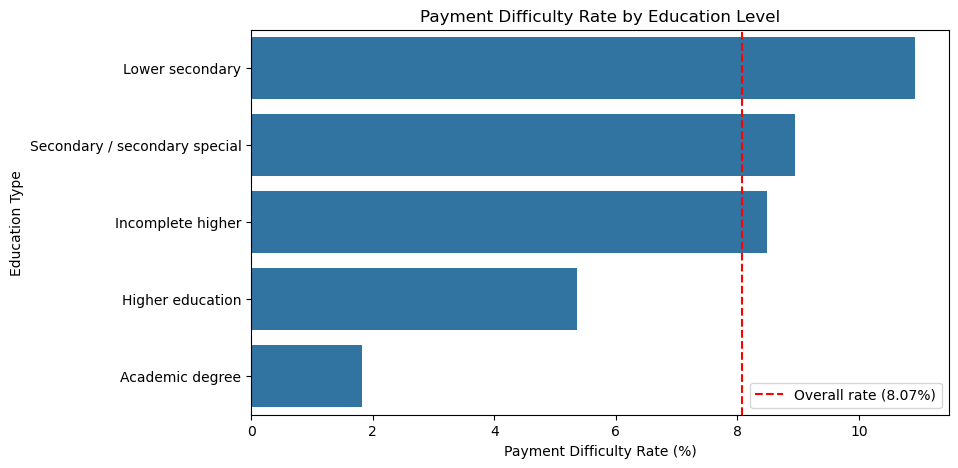

In [39]:
plt.figure(figsize=(9, 5))

sns.barplot(x=education_rate.values, y=education_rate.index)

overall_rate = df_clean['TARGET'].mean() * 100
plt.axvline(overall_rate, color='red', linestyle='--', label=f'Overall rate ({overall_rate:.2f}%)')

plt.title('Payment Difficulty Rate by Education Level')
plt.xlabel('Payment Difficulty Rate (%)')
plt.ylabel('Education Type')
plt.legend()

plt.show()

#### Observation:
- The payment difficulty rate is not the same for all education groups.
- Lower secondary has the highest rate, at about 10.93%, which is above the overall rate of 8.07%.
- Academic degree has the lowest rate, at about 1.83%, but it is a very small group, so this value should be interpreted with caution.
- Customers with higher education (5.36%) have a lower rate than customers with lower secondary education (10.93%).
- Secondary / secondary special (8.94%) and Incomplete higher (8.48%) are slightly above the overall rate.
- Overall, the payment difficulty rate decreases as the education level increases.
- This shows that education level may be a useful feature for the model. It does not mean that education causes payment difficulties.

### 8.7 Employment Duration Distribution

I will analyze the `YEARS_EMPLOYED` column to understand how long customers have been working in their current job.

A histogram will show how employment duration is spread across customers. Since a few customers have very long employment, I will limit the chart to the 99th percentile to keep it readable. This only affects the chart and does not remove any records from the data.

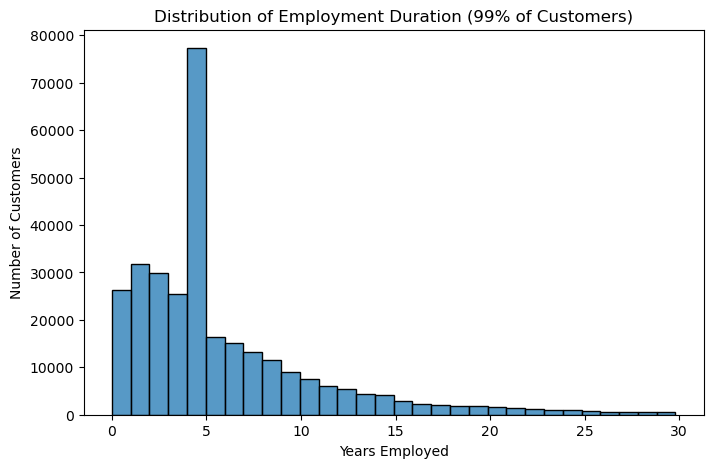

In [40]:
upper_limit = df_clean['YEARS_EMPLOYED'].quantile(0.99)

plt.figure(figsize=(8, 5))

sns.histplot(
    data=df_clean[df_clean['YEARS_EMPLOYED'] <= upper_limit],
    x='YEARS_EMPLOYED',
    bins=30
)

plt.title('Distribution of Employment Duration (99% of Customers)')
plt.xlabel('Years Employed')
plt.ylabel('Number of Customers')

plt.show()

#### Observation:
- Most customers have been employed for 0 to 5 years.
- The number of customers decreases as years of employment increase, so the distribution is right-skewed.
- There is one very tall bar at about 4.5 to 5 years. This is not a real pattern. It happened because the unusual 365243 values in DAYS_EMPLOYED were replaced with the median during cleaning, so many customers now share the same value.
- Only a few customers have employment longer than 20 years.
- I need to remember this artificial spike when I interpret YEARS_EMPLOYED in later steps and when I build the model.

### 8.8 Credit Amount Distribution

I will analyze the `AMT_CREDIT` column to understand the size of the loans that customers applied for.

A histogram will show how the loan amounts are spread. Since a few customers have very large loans, I will limit the chart to the 99th percentile to keep it readable. This only affects the chart and does not remove any records from the data.

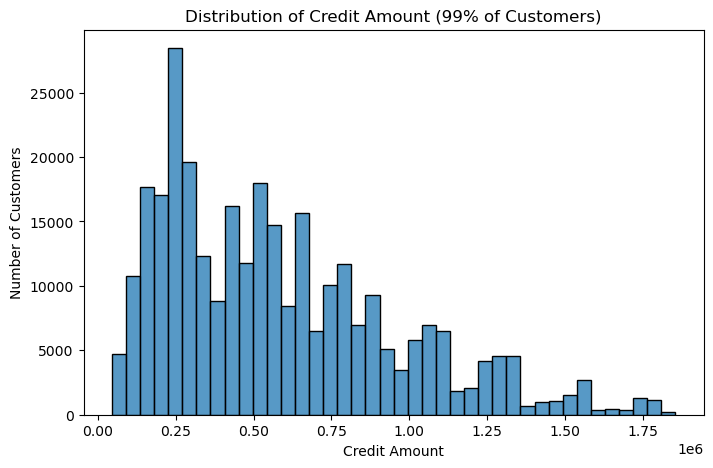

In [41]:
upper_limit = df_clean['AMT_CREDIT'].quantile(0.99)

plt.figure(figsize=(8, 5))

sns.histplot(
    data=df_clean[df_clean['AMT_CREDIT'] <= upper_limit],
    x='AMT_CREDIT',
    bins=40
)

plt.title('Distribution of Credit Amount (99% of Customers)')
plt.xlabel('Credit Amount')
plt.ylabel('Number of Customers')

plt.show()

#### Observation:
- Most customers applied for loans between about 100,000 and 900,000.
- The highest concentration is around 250,000.
- The number of customers decreases as the credit amount increases, so the distribution is right-skewed.
- The distribution has several small peaks. This is likely because people often apply for round loan amounts.
- Only a small number of customers have very large loan amounts (above about 1,500,000).

### 8.9 Financial Amounts vs TARGET

I will compare four financial columns (`AMT_INCOME_TOTAL`, `AMT_CREDIT`, `AMT_ANNUITY`, `AMT_GOODS_PRICE`) between customers with and without payment difficulties.

I will use box plots because they show the median and the spread of values for each group. These columns have many extreme values, so I will hide the extreme points in the chart (`showfliers=False`) to keep it readable. This only affects the chart and does not remove any records. I will also compare the median values in a table, because the median is not affected much by extreme values.

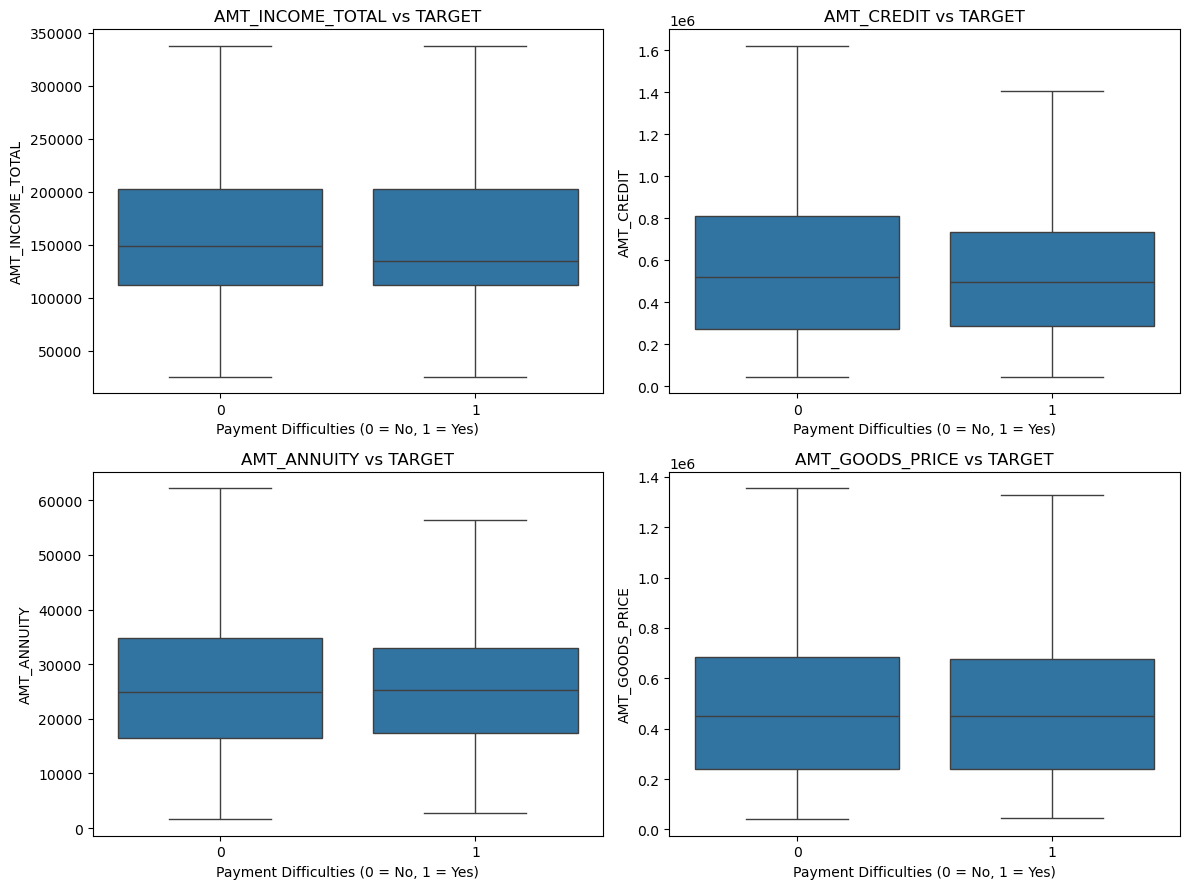

In [42]:
financial_cols = ['AMT_INCOME_TOTAL', 'AMT_CREDIT', 'AMT_ANNUITY', 'AMT_GOODS_PRICE']

fig, axes = plt.subplots(2, 2, figsize=(12, 9))
axes = axes.flatten()

for i, col in enumerate(financial_cols):
    sns.boxplot(data=df_clean, x='TARGET', y=col, showfliers=False, ax=axes[i])
    axes[i].set_title(f'{col} vs TARGET')
    axes[i].set_xlabel('Payment Difficulties (0 = No, 1 = Yes)')
    axes[i].set_ylabel(col)

plt.tight_layout()
plt.show()

#### Observation:
- The median income of customers with payment difficulties is 135,000, compared to 148,500 for customers without difficulties. This is about 9% lower and is the largest difference among the four columns.
- The median AMT_CREDIT is 497,520 for TARGET = 1 and 517,788 for TARGET = 0, about 4% lower for customers with difficulties.
- The median AMT_ANNUITY is almost the same for both groups (25,263 vs 24,876).
- The median AMT_GOODS_PRICE is exactly the same (450,000) for both groups.
- The differences between the two groups are small for all four columns.
- Credit amount, annuity, and goods price look similar to each other, which makes sense because they are related.
- Financial amounts alone do not clearly separate the two groups. The model will need to use other features together with them.

### 8.10 Correlation Analysis

I will calculate the correlation of all numerical columns with `TARGET` to find which features have the strongest relationship with payment difficulties.

Correlation is a number between -1 and 1:
- A positive value means that when the feature increases, payment difficulties tend to increase.
- A negative value means that when the feature increases, payment difficulties tend to decrease.
- A value close to 0 means a weak relationship.

I will show the 10 features with the strongest correlation (positive or negative). I am not using SK_ID_CURR because it is only an ID number.

In [43]:
num_df = df_clean.select_dtypes(include=np.number).drop(columns=['SK_ID_CURR'])

corr_with_target = num_df.corr()['TARGET'].drop('TARGET')

top_features = corr_with_target.abs().sort_values(ascending=False).head(10).index
top_corr = corr_with_target[top_features].sort_values()

print(top_corr.round(3))

EXT_SOURCE_2                  -0.160
EXT_SOURCE_3                  -0.156
EXT_SOURCE_1                  -0.099
AGE                           -0.078
YEARS_EMPLOYED                -0.063
DAYS_LAST_PHONE_CHANGE         0.055
REGION_RATING_CLIENT           0.059
REGION_RATING_CLIENT_W_CITY    0.061
DAYS_EMPLOYED                  0.063
DAYS_BIRTH                     0.078
Name: TARGET, dtype: float64


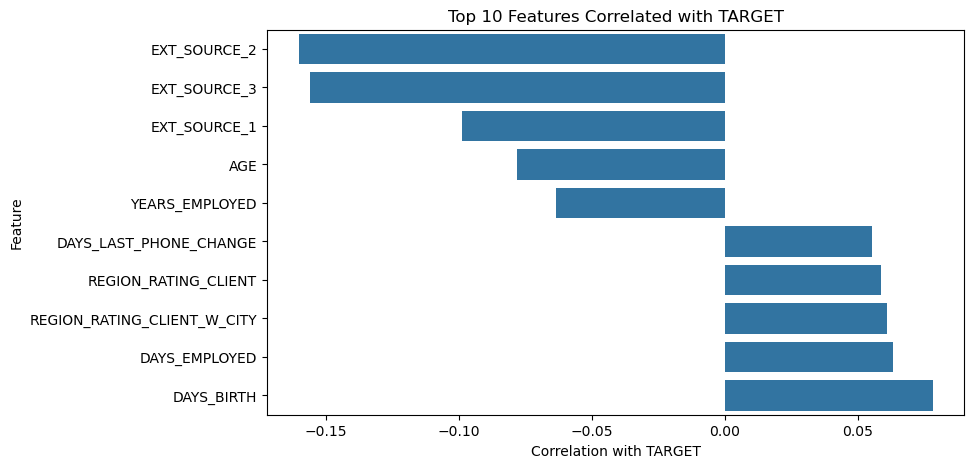

In [44]:
plt.figure(figsize=(9, 5))

sns.barplot(x=top_corr.values, y=top_corr.index)

plt.title('Top 10 Features Correlated with TARGET')
plt.xlabel('Correlation with TARGET')
plt.ylabel('Feature')

plt.show()

#### Observation:
- EXT_SOURCE_2 (-0.160) and EXT_SOURCE_3 (-0.156) have the strongest negative correlation with TARGET, followed by EXT_SOURCE_1 (-0.099). Higher external credit scores are linked with fewer payment difficulties.
- AGE (-0.078) and YEARS_EMPLOYED (-0.063) also have a negative correlation, which means older and longer-employed customers tend to have fewer payment difficulties.
- REGION_RATING_CLIENT (0.059), REGION_RATING_CLIENT_W_CITY (0.061) and DAYS_LAST_PHONE_CHANGE (0.055) have a weak positive correlation with TARGET.
- DAYS_BIRTH and DAYS_EMPLOYED show the same relationship as AGE and YEARS_EMPLOYED with the opposite sign, because AGE and YEARS_EMPLOYED were created from them.
- All correlations are weak (the highest is about 0.16 in size), so no single feature can predict payment difficulties on its own. The model will need to use many features together.
- Correlation only shows a straight-line relationship and does not prove cause.

### EDA Summary

In this section, I explored the cleaned dataset to understand the customers and to find patterns related to payment difficulties.

**1. Target variable**
- Only about 8.07% of customers faced payment difficulties, and 91.93% did not.
- The dataset is highly imbalanced, so accuracy alone will not be a good metric. I will also use precision, recall, F1-score and ROC-AUC.

**2. Customer profile**
- Most customers are between 25 and 60 years old, with the highest concentration around 38 to 40 years.
- Most customers have an income between 75,000 and 225,000. The income distribution is right-skewed.
- About 66% of applicants are female and about 34% are male.
- About 71% of customers have secondary education and about 24% have higher education.
- Most customers have been employed for 0 to 5 years.
- Most loans are between about 100,000 and 900,000, and the credit amount is right-skewed.

**3. Relationship with payment difficulties**
- Payment difficulty rate decreases as education level increases. It is highest for Lower secondary (10.93%) and lowest for Higher education (5.36%). Academic degree (1.83%) is a very small group, so it should be interpreted with caution.
- Income, credit amount, annuity and goods price show only small differences between the two groups. Customers with payment difficulties have a slightly lower median income (135,000 vs 148,500).
- The external credit scores (EXT_SOURCE_2, EXT_SOURCE_3, EXT_SOURCE_1) have the strongest relationship with TARGET. Higher scores are linked with fewer payment difficulties.
- AGE and YEARS_EMPLOYED also have a weak negative correlation with TARGET.
- All correlations are weak (the strongest is about -0.16), so no single feature can predict payment difficulties. The model needs to use many features together.

**4. Points to remember for the next sections**
- DAYS_BIRTH and DAYS_EMPLOYED duplicate AGE and YEARS_EMPLOYED, so I will remove them during preprocessing.
- YEARS_EMPLOYED has an artificial spike at about 4.5 to 5 years, caused by median imputation of the 365243 values. I will mention this in the Challenges section.
- Missing values were filled before the train-test split during cleaning. To avoid data leakage, I will split the data first and fit the imputation on training data only, using a Scikit-learn pipeline.
- Correlation shows only a straight-line relationship and does not prove cause.

## 9. Data Preprocessing

### 9.1 Preparing the Modeling Data and Separating Features and Target

In Section 7, missing values were filled using the full dataset before splitting the data. This can cause data leakage, because the test data would influence the values used for training.

To avoid this, I will create a modeling copy (`df_model`) that keeps all the cleaning results (dropped columns, AGE, YEARS_EMPLOYED, XNA handling) but puts back the original missing values. After the train-test split, I will fill the missing values using the training data only.

Then I will separate the data into:
- **X (features):** the columns used to make predictions.
- **y (target):** the `TARGET` column.

I am removing `SK_ID_CURR` from X because it is only an ID number and has no useful information for prediction.

In [45]:
df_model = df_clean.copy()

for col in df_model.columns:
    if col in df.columns:
        df_model[col] = df_clean[col].where(df[col].notna())

mask = df['DAYS_EMPLOYED'] == 365243
df_model.loc[mask, ['DAYS_EMPLOYED', 'YEARS_EMPLOYED']] = np.nan

print("Shape of df_model:", df_model.shape)
print("Total missing values:", df_model.isnull().sum().sum())

Shape of df_model: (307511, 107)
Total missing values: 5694865


In [46]:
X = df_model.drop(columns=['TARGET', 'SK_ID_CURR'])
y = df_model['TARGET']

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (307511, 105)
y shape: (307511,)


### 9.2 Removing Duplicate Features

During cleaning, I created `AGE` from `DAYS_BIRTH` and `YEARS_EMPLOYED` from `DAYS_EMPLOYED`. The new columns carry the same information as the old ones, only in years instead of negative days.

Keeping both would repeat the same information in the model. Also, `DAYS_BIRTH` and `DAYS_EMPLOYED` are stored as negative numbers, which is harder to read and explain.

First, I will confirm that the columns are duplicates by checking their correlation. A correlation of -1 means they are exactly the same information with the sign flipped. Then I will remove `DAYS_BIRTH` and `DAYS_EMPLOYED` from the features (X).

In [47]:
print("AGE vs DAYS_BIRTH:", round(X['AGE'].corr(X['DAYS_BIRTH']), 4))
print("YEARS_EMPLOYED vs DAYS_EMPLOYED:", round(X['YEARS_EMPLOYED'].corr(X['DAYS_EMPLOYED']), 4))

AGE vs DAYS_BIRTH: -0.9997
YEARS_EMPLOYED vs DAYS_EMPLOYED: -1.0


In [48]:
X = X.drop(columns=['DAYS_BIRTH', 'DAYS_EMPLOYED'])

print("X shape:", X.shape)
print("DAYS_BIRTH in X:", 'DAYS_BIRTH' in X.columns)
print("DAYS_EMPLOYED in X:", 'DAYS_EMPLOYED' in X.columns)

X shape: (307511, 103)
DAYS_BIRTH in X: False
DAYS_EMPLOYED in X: False


### 9.3 Train-Test Split

I will split the data into a training set (80%) and a test set (20%). The model learns from the training set, and the test set is kept aside to check how well the model works on new customers.

**Handling class imbalance**

The dataset is highly imbalanced, because only about 8% of customers faced payment difficulties. To handle this, I will:
- Use a **stratified** split (`stratify=y`), so both sets keep the same class ratio.
- Use `class_weight='balanced'` while training the models, so the model gives more importance to the minority class (customers with payment difficulties).
- Evaluate the models using Precision, Recall, F1-score and ROC-AUC instead of accuracy alone.

I am not using resampling methods such as SMOTE in the main models, to keep the project simple. I may test it later as an extra experiment.

I am using `random_state=42` so that the split is the same every time I run the notebook.

In [49]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)
print("y_train shape:", y_train.shape)
print("y_test shape:", y_test.shape)

X_train shape: (246008, 103)
X_test shape: (61503, 103)
y_train shape: (246008,)
y_test shape: (61503,)


In [50]:
print("Training set (%):")
print((y_train.value_counts(normalize=True) * 100).round(2))

print()
print("Test set (%):")
print((y_test.value_counts(normalize=True) * 100).round(2))# Check that both sets keep the same class ratio
print("Training set (%):")
print((y_train.value_counts(normalize=True) * 100).round(2))

print()
print("Test set (%):")
print((y_test.value_counts(normalize=True) * 100).round(2))

Training set (%):
TARGET
0    91.93
1     8.07
Name: proportion, dtype: float64

Test set (%):
TARGET
0    91.93
1     8.07
Name: proportion, dtype: float64
Training set (%):
TARGET
0    91.93
1     8.07
Name: proportion, dtype: float64

Test set (%):
TARGET
0    91.93
1     8.07
Name: proportion, dtype: float64


### 9.4 Identifying Numerical and Categorical Columns

Numerical and categorical columns need different preprocessing:
- **Numerical columns:** missing values will be filled with the median, and the values will be scaled.
- **Categorical columns:** missing values will be filled with the most frequent value (mode), and the text categories will be converted into numbers using one-hot encoding.

I will first identify both column types using the training data, and check how many unique categories each categorical column has. Columns with many categories will create many new columns after encoding.

In [51]:
numerical_cols = X_train.select_dtypes(include=np.number).columns.tolist()
categorical_cols = X_train.select_dtypes(include='object').columns.tolist()

print("Number of numerical columns:", len(numerical_cols))
print("Number of categorical columns:", len(categorical_cols))
print("Total:", len(numerical_cols) + len(categorical_cols))

Number of numerical columns: 88
Number of categorical columns: 15
Total: 103


In [52]:
print(X_train[categorical_cols].nunique().sort_values(ascending=False))

ORGANIZATION_TYPE             58
OCCUPATION_TYPE               18
NAME_INCOME_TYPE               8
NAME_TYPE_SUITE                7
WEEKDAY_APPR_PROCESS_START     7
WALLSMATERIAL_MODE             7
NAME_FAMILY_STATUS             6
NAME_HOUSING_TYPE              6
NAME_EDUCATION_TYPE            5
HOUSETYPE_MODE                 3
NAME_CONTRACT_TYPE             2
CODE_GENDER                    2
FLAG_OWN_CAR                   2
FLAG_OWN_REALTY                2
EMERGENCYSTATE_MODE            2
dtype: int64


In [53]:
missing_train = (X_train.isnull().mean() * 100).sort_values(ascending=False)
print(missing_train.head(10).round(2))

LANDAREA_MODE         59.34
LANDAREA_AVG          59.34
LANDAREA_MEDI         59.34
BASEMENTAREA_MEDI     58.47
BASEMENTAREA_AVG      58.47
BASEMENTAREA_MODE     58.47
EXT_SOURCE_1          56.34
NONLIVINGAREA_AVG     55.13
NONLIVINGAREA_MEDI    55.13
NONLIVINGAREA_MODE    55.13
dtype: float64


### 9.5 Building the Preprocessing Pipeline

I will build one preprocessing pipeline that prepares the numerical and categorical columns in different ways.

**Numerical columns (88):**
- Fill missing values with the **median**.
- Scale the values using `StandardScaler`, so all columns are on a similar scale. This helps Logistic Regression.

**Categorical columns (15):**
- Fill missing values with the **most frequent value (mode)**.
- Convert the text categories into numbers using **one-hot encoding**. `handle_unknown='ignore'` makes sure that a category seen only in the test data does not cause an error.

**Avoiding data leakage:** I will fit the pipeline on the training data only (`fit_transform` on X_train). Then I will apply the same medians, modes and scaling to the test data (`transform` on X_test). The test data is never used to learn anything.

In [54]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

numerical_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')), 
    ('scaler', StandardScaler())
])

categorical_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore'))
])

preprocessor = ColumnTransformer(
    transformers=[
        ('num', numerical_pipeline, numerical_cols),
        ('cat', categorical_pipeline, categorical_cols)
    ]
)

In [55]:
X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

print("X_train_processed shape:", X_train_processed.shape)
print("X_test_processed shape:", X_test_processed.shape)

X_train_processed shape: (246008, 223)
X_test_processed shape: (61503, 223)


In [56]:
print("Missing values in train:", np.isnan(X_train_processed).sum())
print("Missing values in test:", np.isnan(X_test_processed).sum())

Missing values in train: 0
Missing values in test: 0


## 10. Model Building

In this section, I will build three simple models and compare them later:
1. Logistic Regression
2. Decision Tree
3. Random Forest

All models are trained on the preprocessed training data (`X_train_processed`, `y_train`). Because the dataset is imbalanced, I will use `class_weight='balanced'` in every model, so that mistakes on customers with payment difficulties are treated as more important.

### 10.1 Logistic Regression

Logistic Regression is a simple model that calculates the probability that a customer will face payment difficulties. It is a good first model because it is fast and easy to explain.

I will train it on the training data, and then make predictions on the test data. I will save two things:
- The predicted class (0 or 1).
- The predicted probability of class 1, which I will use later for ROC-AUC and customer risk segmentation.

In [57]:
from sklearn.linear_model import LogisticRegression

log_model = LogisticRegression(
    class_weight='balanced', 
    max_iter= 1000, 
    random_state=42
)

log_model.fit(X_train_processed, y_train)

,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,'balanced'
,random_state,42
,solver,'lbfgs'
,max_iter,1000
,multi_class,'deprecated'


In [58]:
y_pred_log = log_model.predict(X_test_processed)
y_prob_log = log_model.predict_proba(X_test_processed)[:, 1]

print("Predicted classes (%):")
print((pd.Series(y_pred_log).value_counts(normalize=True) * 100).round(2))

print()
print("First 5 predicted probabilities:", y_prob_log[:5].round(3))

Predicted classes (%):
0    66.1
1    33.9
Name: proportion, dtype: float64

First 5 predicted probabilities: [0.361 0.315 0.787 0.567 0.598]


#### Observation:
- The Logistic Regression model was trained using `class_weight='balanced'` on the preprocessed training data.
- The model predicts 33.9% of test customers as class 1 (payment difficulties) and 66.1% as class 0. This is much higher than the real rate of 8.07%, because the balanced class weights make the model more sensitive to the minority class.
- This means the model is likely to find more customers with payment difficulties (higher recall), but it will also flag many customers who would not face difficulties (lower precision).
- The predicted probabilities are higher than the real chance of difficulties because of the class weights, so I will use them to rank customers by risk, not as exact percentages.
- The model will be evaluated in Section 11.

**Summary:** I trained a Logistic Regression model with balanced class weights and saved its predictions and probabilities for evaluation.

### 10.2 Decision Tree

A Decision Tree makes predictions by asking a series of yes/no questions about the customer's data (for example, "Is EXT_SOURCE_2 below 0.5?"). It is easy to explain, because the rules can be followed step by step.

A tree with no limit keeps asking questions until it memorizes the training data. This is called **overfitting**, and the model then performs badly on new customers. To prevent this, I will limit the tree with:
- `max_depth=6`: the tree can ask at most 6 questions in a row.
- `min_samples_leaf=100`: every final group must contain at least 100 customers, so the tree does not make rules for tiny groups.

I will use `class_weight='balanced'` again to handle the imbalance, and save the predicted classes and probabilities as before.

In [59]:
from sklearn.tree import DecisionTreeClassifier

tree_model = DecisionTreeClassifier(
    max_depth=6, 
    min_samples_leaf=100, 
    class_weight='balanced', 
    random_state=42
)

tree_model.fit(X_train_processed, y_train)

,criterion,'gini'
,splitter,'best'
,max_depth,6
,min_samples_split,2
,min_samples_leaf,100
,min_weight_fraction_leaf,0.0
,max_features,None
,random_state,42
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,class_weight,'balanced'


In [60]:
y_pred_tree = tree_model.predict(X_test_processed)
y_prob_tree = tree_model.predict_proba(X_test_processed)[:,1]

print("Predicted Classes (%):")
print((pd.Series(y_pred_tree).value_counts(normalize=True) * 100).round(2))

print("\nFirst 5 predicted probabilities:", y_prob_tree[:5].round(3))

Predicted Classes (%):
0    65.32
1    34.68
Name: proportion, dtype: float64

First 5 predicted probabilities: [0.574 0.263 0.818 0.334 0.368]


#### Observation:
- The Decision Tree was trained using `class_weight='balanced'`, with `max_depth=6` and `min_samples_leaf=100` to prevent overfitting.
- The model predicts 34.68% of test customers as class 1 (payment difficulties) and 65.32% as class 0. This is higher than the real rate of 8.07%, because the balanced class weights make the model more sensitive to the minority class.
- The percentage of customers flagged is very similar to Logistic Regression (33.9%), so the models need to be compared using Precision, Recall, F1-score and ROC-AUC.
- Customers in the same final group of the tree get the same probability, so the probabilities are less detailed than those of Logistic Regression.
- The model will be evaluated in Section 11.

**Summary:** I trained a depth-limited Decision Tree with balanced class weights and saved its predictions and probabilities for evaluation.

### 10.3 Random Forest

A Random Forest builds many Decision Trees (here 100) and combines their answers. Each tree sees a different random part of the data, so the mistakes of one tree are often fixed by the others. This usually works better than a single tree.

To keep the model simple and fast on this dataset, I will limit each tree with:
- `n_estimators=100`: the forest has 100 trees.
- `max_depth=10`: each tree can ask at most 10 questions in a row.
- `min_samples_leaf=50`: every final group must contain at least 50 customers, to avoid overfitting.
- `n_jobs=-1`: use all available CPU cores to train faster.

I will use `class_weight='balanced'` again to handle the imbalance, and save the predicted classes and probabilities as before.

In [61]:
from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(
    n_estimators=100,
    max_depth=10,
    min_samples_leaf=50,
    class_weight='balanced',
    n_jobs=-1,
    random_state=42
)

rf_model.fit(X_train_processed, y_train)

,n_estimators,100
,criterion,'gini'
,max_depth,10
,min_samples_split,2
,min_samples_leaf,50
,min_weight_fraction_leaf,0.0
,max_features,'sqrt'
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


In [62]:
y_pred_rf = rf_model.predict(X_test_processed)
y_prob_rf = rf_model.predict_proba(X_test_processed)[:, 1]  

print("Predicted classes (%):")
print((pd.Series(y_pred_rf).value_counts(normalize=True) * 100).round(2))

print()
print("First 5 predicted probabilities:", y_prob_rf[:5].round(3))

Predicted classes (%):
0    68.6
1    31.4
Name: proportion, dtype: float64

First 5 predicted probabilities: [0.458 0.392 0.58  0.476 0.529]


#### Observation:
- The Random Forest was trained with 100 trees using `class_weight='balanced'`, with `max_depth=10` and `min_samples_leaf=50` to prevent overfitting.
- The model predicts 31.4% of test customers as class 1 (payment difficulties) and 68.6% as class 0. This is higher than the real rate of 8.07%, because the balanced class weights make the model more sensitive to the minority class.
- All three models flag a similar share of customers as class 1 (Logistic Regression 33.9%, Decision Tree 34.68%, Random Forest 31.4%), so they need to be compared using Precision, Recall, F1-score and ROC-AUC.
- The probabilities are the average of many trees, so they are more detailed than those of the single Decision Tree. They are close to 0.5 for many customers, so I will use them to rank customers by risk, not as exact percentages.
- All three models are now trained. They will be compared in Section 11 using Precision, Recall, F1-score, Confusion Matrix and ROC-AUC.

**Summary:** I trained a depth-limited Random Forest with balanced class weights and saved its predictions and probabilities for evaluation.

## 11. Model Evaluation

The dataset is highly imbalanced, so accuracy alone is not enough. A model that predicts "no payment difficulties" for every customer would get about 92% accuracy, but it would find zero customers with difficulties.

I will evaluate each model on the test data using:
- **Precision:** Of all customers the model flagged as class 1, how many really had payment difficulties?
- **Recall:** Of all customers who really had payment difficulties, how many did the model find?
- **F1-score:** One number that balances precision and recall.
- **Confusion Matrix:** A table showing correct and wrong predictions for each class.
- **ROC-AUC:** How well the model separates the two classes using its probabilities. 0.5 means random guessing, and 1.0 means perfect.
- **Accuracy:** Shown for completeness, but not used to judge the models.

For this project, **recall and ROC-AUC** are the most important, because the goal is to identify customers who may face payment difficulties.

### 11.1 Logistic Regression Evaluation

In [63]:
from sklearn.metrics import (
    classification_report, confusion_matrix,
    accuracy_score, precision_score, recall_score, f1_score, roc_auc_score
)

print("Logistic Regression - Classification Report")
print(classification_report(y_test, y_pred_log, target_names=['No Difficulty (0)', 'Difficulty (1)']))

Logistic Regression - Classification Report
                   precision    recall  f1-score   support

No Difficulty (0)       0.96      0.69      0.80     56538
   Difficulty (1)       0.16      0.68      0.26      4965

         accuracy                           0.69     61503
        macro avg       0.56      0.68      0.53     61503
     weighted avg       0.90      0.69      0.76     61503



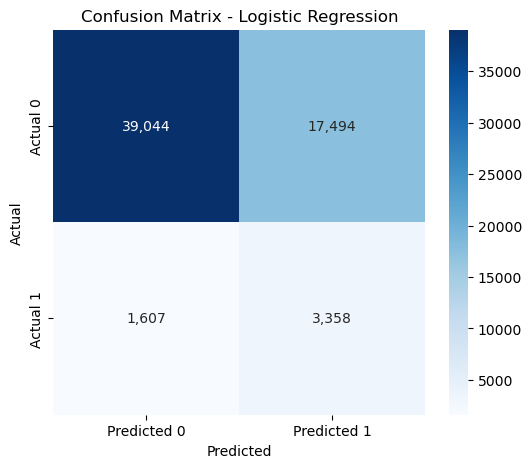

In [64]:
cm_log = confusion_matrix(y_test, y_pred_log)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm_log, annot=True, fmt=',d', cmap='Blues',
    xticklabels=['Predicted 0', 'Predicted 1'],
    yticklabels=['Actual 0', 'Actual 1']
)

plt.title('Confusion Matrix - Logistic Regression')
plt.xlabel('Predicted')
plt.ylabel('Actual')

plt.show()

In [65]:
roc_auc_log = roc_auc_score(y_test, y_prob_log)
print("Logistic Regression ROC-AUC:", round(roc_auc_log, 4))

results = {}
results['Logistic Regression'] = {
    'Accuracy': accuracy_score(y_test, y_pred_log),
    'Precision': precision_score(y_test, y_pred_log),
    'Recall': recall_score(y_test, y_pred_log),
    'F1-score': f1_score(y_test, y_pred_log),
    'ROC-AUC': roc_auc_log
}

print(pd.DataFrame(results).T.round(4))

Logistic Regression ROC-AUC: 0.7483
                     Accuracy  Precision  Recall  F1-score  ROC-AUC
Logistic Regression    0.6894      0.161  0.6763    0.2601   0.7483


#### Observation:
- Logistic Regression achieved an accuracy of 0.69, but accuracy is not reliable here because the dataset is highly imbalanced. A model that predicts "no difficulty" for everyone would get about 92% accuracy without finding any customer with difficulties.
- The model found 3,358 of the 4,965 customers who really had payment difficulties, so the recall for class 1 is 0.68 (about 68%). It missed 1,607 customers (about 32%).
- The precision for class 1 is 0.16, which means that only about 16 out of 100 flagged customers really faced payment difficulties. The model flagged 17,494 customers who did not have difficulties (false alarms).
- A flagged customer is about twice as likely to face payment difficulties as a random customer, because the real rate in the data is only 8.07%.
- The F1-score for class 1 is 0.26, which is low because of the low precision.
- The ROC-AUC is 0.7483, which shows that the model separates the two groups better than random guessing (0.5), but it is not very strong.
- The balanced class weights improved recall but reduced precision. This is a trade-off.

**Summary:** Logistic Regression finds about two out of three customers with payment difficulties, but it also flags many customers who would not face difficulties.

### 11.2 Decision Tree Evaluation

I will evaluate the Decision Tree on the test data using the same metrics as Logistic Regression: classification report, confusion matrix, ROC-AUC, and the summary metrics. This keeps the comparison fair.

In [66]:
print("Decision Tree - Classification Report")
print(classification_report(y_test, y_pred_tree, target_names=['No Difficulty (0)', 'Difficulty (1)']))

Decision Tree - Classification Report
                   precision    recall  f1-score   support

No Difficulty (0)       0.96      0.68      0.79     56538
   Difficulty (1)       0.15      0.64      0.24      4965

         accuracy                           0.68     61503
        macro avg       0.55      0.66      0.52     61503
     weighted avg       0.89      0.68      0.75     61503



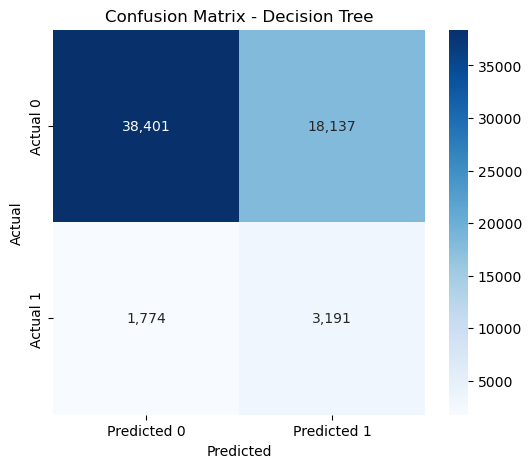

In [67]:
cm_tree = confusion_matrix(y_test, y_pred_tree)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm_tree, annot=True, fmt=',d', cmap='Blues',
    xticklabels=['Predicted 0', 'Predicted 1'],
    yticklabels=['Actual 0', 'Actual 1']
)

plt.title('Confusion Matrix - Decision Tree')
plt.xlabel('Predicted')
plt.ylabel('Actual')

plt.show()

In [68]:
roc_auc_tree = roc_auc_score(y_test, y_prob_tree)
print("Decision Tree ROC-AUC:", round(roc_auc_tree, 4))

results['Decision Tree'] = {
    'Accuracy': accuracy_score(y_test, y_pred_tree),
    'Precision': precision_score(y_test, y_pred_tree),
    'Recall': recall_score(y_test, y_pred_tree),
    'F1-score': f1_score(y_test, y_pred_tree),
    'ROC-AUC': roc_auc_tree
}

print(pd.DataFrame(results).T.round(4))

Decision Tree ROC-AUC: 0.7165
                     Accuracy  Precision  Recall  F1-score  ROC-AUC
Logistic Regression    0.6894     0.1610  0.6763    0.2601   0.7483
Decision Tree          0.6763     0.1496  0.6427    0.2427   0.7165


#### Observation:
- The Decision Tree achieved an accuracy of 0.68, but accuracy is not reliable here because the dataset is highly imbalanced.
- The model found 3,191 of the 4,965 customers who really had payment difficulties, so the recall for class 1 is 0.64 (about 64%). It missed 1,774 customers (about 36%).
- The precision for class 1 is 0.15, which means that only about 15 out of 100 flagged customers really faced payment difficulties. The model flagged 18,137 customers who did not have difficulties (false alarms).
- A flagged customer is about twice as likely to face payment difficulties as a random customer, because the real rate in the data is only 8.07%.
- The F1-score for class 1 is 0.24.
- The ROC-AUC is 0.7165, which is lower than Logistic Regression (0.7483). This means the Decision Tree ranks customers by risk less well.
- Compared with Logistic Regression, the Decision Tree found fewer customers with payment difficulties (3,191 vs 3,358) and raised more false alarms (18,137 vs 17,494).

**Summary:** The Decision Tree is simple and easy to explain, but it performs slightly worse than Logistic Regression on every metric.

### 11.3 Random Forest Evaluation

I will evaluate the Random Forest on the test data using the same metrics as the other two models: classification report, confusion matrix, ROC-AUC, and the summary metrics. This keeps the comparison fair.

In [69]:
print("Random Forest - Classification Report")
print(classification_report(y_test, y_pred_rf, target_names=['No Difficulty (0)', 'Difficulty (1)']))

Random Forest - Classification Report
                   precision    recall  f1-score   support

No Difficulty (0)       0.96      0.71      0.82     56538
   Difficulty (1)       0.16      0.63      0.26      4965

         accuracy                           0.71     61503
        macro avg       0.56      0.67      0.54     61503
     weighted avg       0.89      0.71      0.77     61503



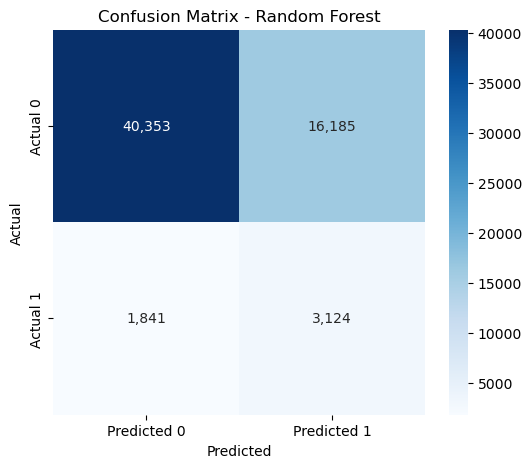

In [70]:
cm_rf = confusion_matrix(y_test, y_pred_rf)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm_rf, annot=True, fmt=',d', cmap='Blues',
    xticklabels=['Predicted 0', 'Predicted 1'],
    yticklabels=['Actual 0', 'Actual 1']
)

plt.title('Confusion Matrix - Random Forest')
plt.xlabel('Predicted')
plt.ylabel('Actual')

plt.show()

In [71]:
roc_auc_rf = roc_auc_score(y_test, y_prob_rf)
print("Random Forest ROC-AUC:", round(roc_auc_rf, 4))

results['Random Forest'] = {
    'Accuracy': accuracy_score(y_test, y_pred_rf),
    'Precision': precision_score(y_test, y_pred_rf),
    'Recall': recall_score(y_test, y_pred_rf),
    'F1-score': f1_score(y_test, y_pred_rf),
    'ROC-AUC': roc_auc_rf
}

print(pd.DataFrame(results).T.round(4))

Random Forest ROC-AUC: 0.735
                     Accuracy  Precision  Recall  F1-score  ROC-AUC
Logistic Regression    0.6894     0.1610  0.6763    0.2601   0.7483
Decision Tree          0.6763     0.1496  0.6427    0.2427   0.7165
Random Forest          0.7069     0.1618  0.6292    0.2574   0.7350


#### Observation:
- The Random Forest achieved an accuracy of 0.71, which is the highest of the three models. But accuracy is not reliable here because the dataset is highly imbalanced, and the forest has the highest accuracy partly because it flags fewer customers.
- The model found 3,124 of the 4,965 customers who really had payment difficulties, so the recall for class 1 is 0.63 (about 63%). It missed 1,841 customers (about 37%).
- The precision for class 1 is 0.16, which means that only about 16 out of 100 flagged customers really faced payment difficulties. The model flagged 16,185 customers who did not have difficulties (false alarms).
- The F1-score for class 1 is 0.26.
- The ROC-AUC is 0.735, which is higher than the Decision Tree (0.7165) but lower than Logistic Regression (0.7483).
- Compared with Logistic Regression, the Random Forest found fewer customers with payment difficulties (3,124 vs 3,358), but it raised fewer false alarms (16,185 vs 17,494).

**Summary:** The Random Forest ranks customers better than the Decision Tree, but it does not beat Logistic Regression on ROC-AUC or recall.

## 12. Model Comparison

In this section, I will compare the three models using the same test data and the same metrics. The goal is to find which model is best at identifying customers who may face payment difficulties.

Because the dataset is imbalanced, I will focus on **Recall**, **F1-score** and **ROC-AUC**. Accuracy is shown in the table, but it is not used to choose the best model.

### 12.1 Comparison Table

In [72]:
comparison = pd.DataFrame(results).T.round(4)
comparison = comparison.sort_values('ROC-AUC', ascending=False)

comparison

,Accuracy,Precision,Recall,F1-score,ROC-AUC
Logistic Regression,0.6894,0.1610,0.6763,0.2601,0.7483
Random Forest,0.7069,0.1618,0.6292,0.2574,0.7350
Decision Tree,0.6763,0.1496,0.6427,0.2427,0.7165


### 12.2 Metric Comparison Chart

A bar chart makes it easier to compare the models. I am leaving out accuracy, because it is not a reliable metric for imbalanced data.

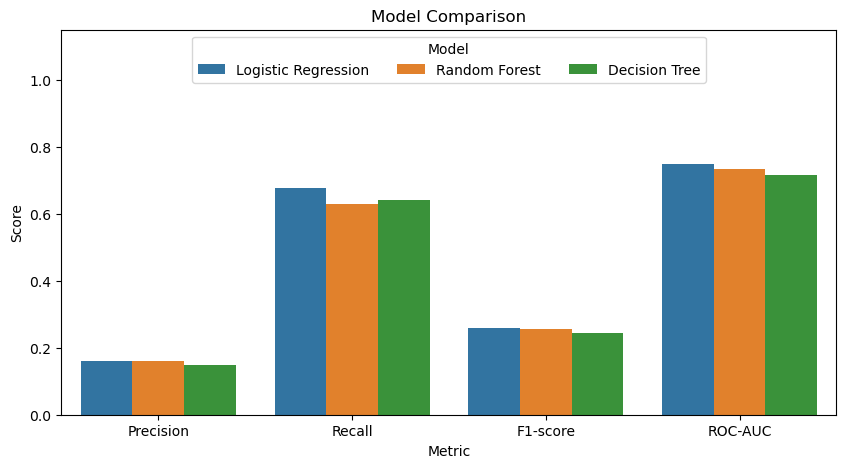

In [73]:
metrics_to_plot = ['Precision', 'Recall', 'F1-score', 'ROC-AUC']

plot_df = comparison[metrics_to_plot].reset_index().melt(
    id_vars='index', var_name='Metric', value_name='Score'
)

plt.figure(figsize=(10, 5))

sns.barplot(data=plot_df, x='Metric', y='Score', hue='index')

plt.title('Model Comparison')
plt.xlabel('Metric')
plt.ylabel('Score')
plt.ylim(0, 1.15)
plt.legend(title='Model', loc='upper center', ncol=3)

plt.show()

### 12.3 ROC Curve Comparison

The ROC curve shows how well each model separates the two groups at every possible probability cut-off. A curve closer to the top-left corner is better. The dashed diagonal line is random guessing (ROC-AUC = 0.5).

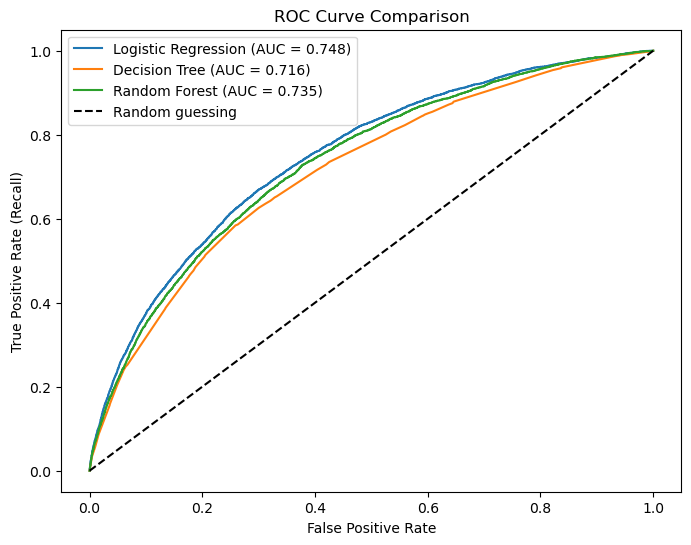

In [74]:
from sklearn.metrics import roc_curve

plt.figure(figsize=(8, 6))

for name, probs in [('Logistic Regression', y_prob_log),
                    ('Decision Tree', y_prob_tree),
                    ('Random Forest', y_prob_rf)]:
    fpr, tpr, _ = roc_curve(y_test, probs)
    auc_value = results[name]['ROC-AUC']
    plt.plot(fpr, tpr, label=f'{name} (AUC = {auc_value:.3f})')

plt.plot([0, 1], [0, 1], 'k--', label='Random guessing')

plt.title('ROC Curve Comparison')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate (Recall)')
plt.legend()

plt.show()

#### Observation:
- Logistic Regression performs best for identifying customers with payment difficulties. It has the highest recall (0.6763), the highest F1-score (0.2601) and the highest ROC-AUC (0.7483).
- Random Forest has the highest accuracy (0.7069) and precision (0.1618), but the accuracy is higher mainly because it flags fewer customers, and the precision is almost the same as the other models. Its recall (0.6292) and ROC-AUC (0.7350) are lower than Logistic Regression.
- Decision Tree has the lowest ROC-AUC (0.7165) and F1-score (0.2427), so it ranks customers by risk less well than the other two models.
- The ROC curves show that all three models are much better than random guessing. The Logistic Regression curve is slightly above the other two, and the Decision Tree curve is the lowest.
- The precision is low for all models (0.15 to 0.16), because only 8.07% of customers really have payment difficulties and the balanced class weights make the models flag many customers.
- The differences between the models are small. None of them is strong enough to be used alone for a real lending decision.
- I will use Logistic Regression as the final model, because it finds the most customers with payment difficulties and ranks customers by risk best. It is also the easiest model to explain.

**Summary:** Logistic Regression is the best of the three models for finding customers with payment difficulties, but all three models are only moderately accurate.

## 13. Customer Risk Segmentation

In this section, I will use the predicted probabilities of the final model (Logistic Regression) to place customers into risk groups.

**Important:** This is not a loan eligibility decision. The model predicts the chance of historical payment difficulties, and the groups only show which customers look riskier compared with other customers.

Because of `class_weight='balanced'`, the predicted probabilities are higher than the real chance of difficulties. So I will not use fixed cut-offs like 0.5. Instead, I will rank the test customers by probability and split them into four equal groups (quartiles): Low, Medium, High and Very High risk.

To check whether the groups are meaningful, I will compare the **actual** payment difficulty rate in each group.

### 13.1 Creating Risk Groups

In [75]:
risk_df = pd.DataFrame({
    'Actual': y_test.values,
    'Probability': y_prob_log
})

risk_df['Risk Group'] = pd.qcut(
    risk_df['Probability'],
    q=4,
    labels=['Low', 'Medium', 'High', 'Very High']
)

risk_summary = risk_df.groupby('Risk Group', observed=True).agg(
    Customers=('Actual', 'count'),
    With_Difficulties=('Actual', 'sum'),
    Actual_Rate=('Actual', 'mean'),
    Min_Probability=('Probability', 'min'),
    Max_Probability=('Probability', 'max')
)

risk_summary['Actual_Rate (%)'] = (risk_summary['Actual_Rate'] * 100).round(2)
risk_summary['Share of All Difficulties (%)'] = (
    risk_summary['With_Difficulties'] / risk_summary['With_Difficulties'].sum() * 100
).round(2)

risk_summary[['Customers', 'With_Difficulties', 'Actual_Rate (%)',
              'Share of All Difficulties (%)', 'Min_Probability', 'Max_Probability']].round(3)

,Customers,With_Difficulties,Actual_Rate (%),Share of All Difficulties (%),Min_Probability,Max_Probability
Risk Group,,,,,,
Low,15376,303,1.97,6.10,0.000,0.263
Medium,15376,616,4.01,12.41,0.263,0.398
High,15375,1211,7.88,24.39,0.398,0.565
Very High,15376,2835,18.44,57.10,0.565,0.976


### 13.2 Actual Payment Difficulty Rate by Risk Group

If the model is useful, the actual payment difficulty rate should increase from the Low group to the Very High group. The red line shows the overall rate (8.07%) for comparison.

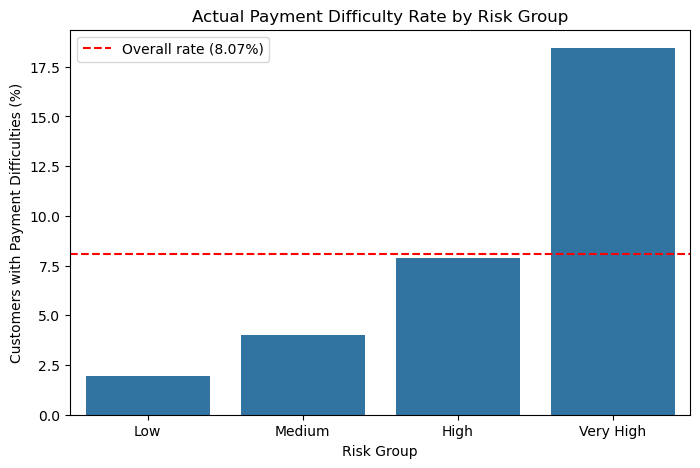

In [76]:
plt.figure(figsize=(8, 5))

sns.barplot(
    x=risk_summary.index,
    y=risk_summary['Actual_Rate (%)']
)

overall_rate = y_test.mean() * 100
plt.axhline(overall_rate, color='red', linestyle='--', label=f'Overall rate ({overall_rate:.2f}%)')

plt.title('Actual Payment Difficulty Rate by Risk Group')
plt.xlabel('Risk Group')
plt.ylabel('Customers with Payment Difficulties (%)')
plt.legend()

plt.show()

#### Observation:
- I divided the test customers into four equal risk groups (Low, Medium, High and Very High) using the Logistic Regression probabilities. Each group has about 15,376 customers.
- The actual payment difficulty rate increases from 1.97% in the Low group to 18.44% in the Very High group (Medium 4.01%, High 7.88%). This shows that the model ranks customers by risk in a meaningful way.
- The Very High group has a rate about 2.3 times higher than the overall rate of 8.07%, and about 9 times higher than the Low group.
- The Very High group contains 57.1% of all customers with payment difficulties (2,835 of 4,965), while the Low group contains only 6.1%.
- The Low and Medium groups are below the overall rate. The High group (7.88%) is close to the overall rate, and only the Very High group is clearly above it.
- Even in the Very High group, about 82% of customers did not face payment difficulties, so the groups show relative risk and not a final decision about a customer.
- These risk groups should not be used as a loan eligibility decision. They can only support other checks, such as a closer review of customers in the High and Very High groups.

**Summary:** The Logistic Regression probabilities sort customers into groups where the actual payment difficulty rate clearly increases from Low to Very High risk, and the Very High group holds more than half of all real payment difficulties.

### 13.3 Key Factors Behind Customer Risk

Task 2 asks for the factors that matter for identifying risky customers. I will find the most important features in two ways:

1. **Logistic Regression coefficients:** A positive coefficient means a higher value of the feature increases the predicted risk. A negative coefficient means it decreases the predicted risk. The numerical columns were scaled, so their coefficients can be compared with each other.
2. **Random Forest feature importance:** This shows how much each feature helped the forest make its predictions. It does not show the direction.

If the same features appear in both lists, I can be more confident that they are really important.

In [77]:
feature_names = preprocessor.get_feature_names_out()
feature_names = [name.replace('num__', '').replace('cat__', '') for name in feature_names]

print("Number of features:", len(feature_names))

Number of features: 223


AMT_GOODS_PRICE                       -0.961
NAME_EDUCATION_TYPE_Academic degree   -0.671
NAME_INCOME_TYPE_Pensioner            -0.611
ORGANIZATION_TYPE_Military            -0.505
EXT_SOURCE_3                          -0.478
NAME_INCOME_TYPE_Unemployed            0.519
ORGANIZATION_TYPE_Transport: type 3    0.528
ORGANIZATION_TYPE_Legal Services       0.653
ORGANIZATION_TYPE_Realtor              0.813
AMT_CREDIT                             0.900
dtype: float64


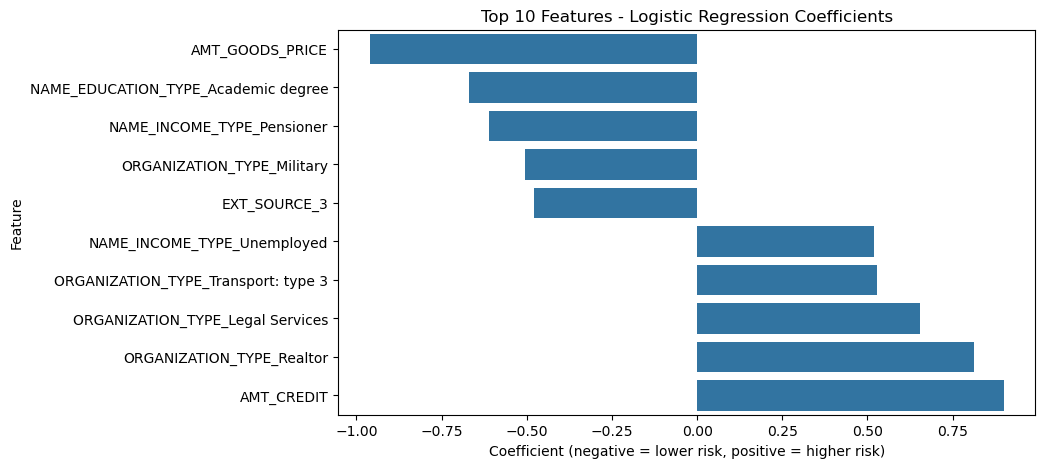

In [78]:
log_coef = pd.Series(log_model.coef_[0], index=feature_names)
top_log = log_coef.reindex(log_coef.abs().sort_values(ascending=False).head(10).index)
top_log = top_log.sort_values()

print(top_log.round(3))

plt.figure(figsize=(9, 5))
sns.barplot(x=top_log.values, y=top_log.index)

plt.title('Top 10 Features - Logistic Regression Coefficients')
plt.xlabel('Coefficient (negative = lower risk, positive = higher risk)')
plt.ylabel('Feature')

plt.show()

EXT_SOURCE_3                            0.1788
EXT_SOURCE_2                            0.1634
EXT_SOURCE_1                            0.0728
YEARS_EMPLOYED                          0.0554
AGE                                     0.0400
AMT_GOODS_PRICE                         0.0273
DAYS_LAST_PHONE_CHANGE                  0.0269
NAME_EDUCATION_TYPE_Higher education    0.0235
AMT_CREDIT                              0.0205
DAYS_ID_PUBLISH                         0.0188
dtype: float64


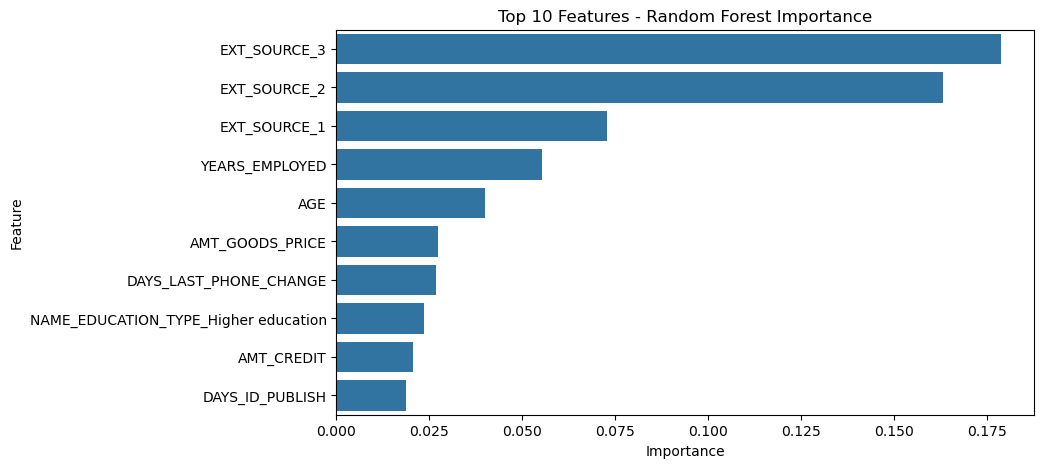

In [79]:
rf_importance = pd.Series(rf_model.feature_importances_, index=feature_names)
top_rf = rf_importance.sort_values(ascending=False).head(10)

print(top_rf.round(4))

plt.figure(figsize=(9, 5))
sns.barplot(x=top_rf.values, y=top_rf.index)

plt.title('Top 10 Features - Random Forest Importance')
plt.xlabel('Importance')
plt.ylabel('Feature')

plt.show()

#### Observation:
- In Random Forest, the most important features are EXT_SOURCE_3 (0.179), EXT_SOURCE_2 (0.163) and EXT_SOURCE_1 (0.073). Together they hold about 41.5% of the total importance. YEARS_EMPLOYED (0.055) and AGE (0.040) come next.
- The top 10 Random Forest features hold about 63% of the total importance.
- In Logistic Regression, EXT_SOURCE_3 has a strong negative coefficient (-0.478), which means a higher external score is linked with a lower predicted risk. This matches the EDA correlation analysis.
- EXT_SOURCE_3 is the clearest factor, because it appears in both lists. Education level (Higher education in Random Forest, Academic degree in Logistic Regression) also appears in both lists and agrees with the EDA finding that the payment difficulty rate decreases as education increases.
- AMT_GOODS_PRICE (-0.961) and AMT_CREDIT (+0.900) have large opposite coefficients in Logistic Regression. These two columns are very similar (a bigger loan means a higher goods price), so their effects cancel each other and should not be interpreted separately.
- Several Logistic Regression coefficients belong to small categories (such as Academic degree, Military, Realtor and Legal Services). Small groups can get large coefficients, so these results are weak evidence.
- NAME_INCOME_TYPE_Pensioner has a negative coefficient. This group is linked with the unusual 365243 values in DAYS_EMPLOYED that were filled with the median, so this coefficient should be interpreted with caution.
- Random Forest importance shows how much a feature is used but not the direction, so I used the Logistic Regression coefficients only as a supporting reference and relied on both models and EDA findings to understand the important features.

## 14. Challenges Faced

This section lists the main challenges I faced in the data and the modeling, the technique I used for each, and the reason for choosing it.

| No. | Challenge | Technique Used | Reason |
|---|---|---|---|
| 1 | Many columns had a high percentage of missing values (up to about 69%). | Dropped 17 columns with more than 60% missing values. Filled the remaining numerical columns with the median and categorical columns with the mode. | Columns with most values missing carry little reliable information. The median is not affected by extreme values, and the mode is the natural choice for categories. |
| 2 | `DAYS_EMPLOYED` had an unusual value (365243) for about 55,000 customers. | Treated it as missing (NaN) and filled it with the median. Converted days into `AGE` and `YEARS_EMPLOYED`. | 365243 days is about 1,000 years, so it is a placeholder, not a real value. Years are easier to read and explain. |
| 3 | The median fill created an artificial spike in `YEARS_EMPLOYED` at about 4.5 to 5 years. | Explained the spike in the EDA. In the final pipeline, I restored these values as missing and filled them using the training data only. | The spike is not a real pattern. It was important not to misread it as customer behavior. |
| 4 | `XNA` values in `CODE_GENDER` and `ORGANIZATION_TYPE`. | Replaced `XNA` in `CODE_GENDER` with the mode, and in `ORGANIZATION_TYPE` with `Unknown`. | `XNA` is a hidden missing value. Gender has only two valid categories, while `ORGANIZATION_TYPE` has a large share of unknown values, so keeping an `Unknown` group avoids guessing. |
| 5 | Financial columns (income, credit, annuity, goods price) had many extreme values. | Kept the genuine extreme values. Used the 99th percentile only to draw charts, and compared medians instead of means. | These are real customers with high incomes or large loans, so removing them would lose information. The chart limit does not change the data. |
| 6 | Data leakage: missing values were first filled using the whole dataset before the train-test split. | Created a modeling copy with the original missing values restored. Split the data first, then fitted the imputation, scaling and encoding on the training data only, using a Scikit-learn pipeline. | If the test data influences the filling values, the test results look better than they really are. The pipeline makes the process clean and repeatable. |
| 7 | `AGE` and `YEARS_EMPLOYED` repeated the information in `DAYS_BIRTH` and `DAYS_EMPLOYED` (correlation of about -1). | Removed `DAYS_BIRTH` and `DAYS_EMPLOYED` from the features. | Keeping both would give the model the same information twice and make the coefficients harder to read. |
| 8 | Text columns, including some with many categories (`ORGANIZATION_TYPE` has 58). | Used one-hot encoding with `handle_unknown='ignore'`. This created 223 columns in total. | Models need numbers. One-hot encoding does not create a false order between categories, and `handle_unknown='ignore'` avoids errors on unseen categories. |
| 9 | Highly imbalanced target (only 8.07% payment difficulties). | Used a stratified split, `class_weight='balanced'` in all three models, and judged the models with Precision, Recall, F1-score and ROC-AUC instead of accuracy. | A model that predicts "no difficulty" for everyone gets about 92% accuracy but finds no defaulters. Balanced weights make the model pay attention to the minority class without creating artificial customers (as SMOTE does). |
| 10 | Precision stayed low (about 0.15 to 0.16) for all models. | Accepted the recall and precision trade-off. Used the probabilities to rank customers into four risk groups. | With 8% real defaulters and balanced weights, the models flag about a third of customers. Ranking by probability is more useful than a single yes/no answer. |
| 11 | The balanced weights made the predicted probabilities higher than the real chance of difficulties. | Used quartiles (equal-sized groups) instead of fixed cut-offs like 0.5, and checked the actual rate in each group. | A probability of 0.6 does not mean a 60% real chance. The actual rate check shows whether the groups are meaningful (from 1.97% to 18.44%). |
| 12 | Models were slow to train and easy to overfit on 246,000 rows and 223 columns. | Limited the depth of the Decision Tree (`max_depth=6`, `min_samples_leaf=100`) and the Random Forest (`max_depth=10`, `min_samples_leaf=50`, 100 trees). | Unlimited trees memorize the training data and take much longer to train. |
| 13 | Features that are almost the same (such as `AMT_CREDIT` and `AMT_GOODS_PRICE`) gave large opposite coefficients in Logistic Regression. | Did not interpret these two coefficients separately. Used Random Forest importance and EDA results to confirm the important factors. | When two features are very similar, the model splits their effect in unstable ways, so a single coefficient can be misleading. |
| 14 | The models performed only moderately (best ROC-AUC 0.7483), and the three models were close to each other. | Compared all models on the same test data and chose Logistic Regression as the final model. | The gap between models is small, so the simplest model that is also best on recall, F1-score and ROC-AUC is the right choice. It is also the easiest to explain. |
| 15 | Only `application_train.csv` was used. The other six files were not used. | Focused on the main application table and kept the project simple. | The extra tables need a lot of aggregation work and careful checks to avoid leakage. This was kept outside the scope because of the short project timeline. |

**Overall learning:** Most of the effort in this project went into data cleaning and avoiding data leakage. The model results are moderate, and the biggest limit is the information available in a single table.

## 15. Conclusion

### 15.1 Project Summary
The goal of this project was to analyze home loan application data and build a model that identifies customers who may face payment difficulties (`TARGET = 1`). The model predicts historical payment difficulties. It does not decide loan eligibility on its own.

I cleaned the main dataset (`application_train.csv`, 307,511 rows), explored it, built three models (Logistic Regression, Decision Tree and Random Forest), compared them, and used the best model to place customers into four risk groups.

### 15.2 Key Findings from the Data
- Only 8.07% of customers faced payment difficulties, so the dataset is highly imbalanced.
- The payment difficulty rate decreases as education level increases (Lower secondary 10.93%, Higher education 5.36%).
- Income, credit amount, annuity and goods price show only small differences between the two groups.
- The external credit scores (EXT_SOURCE_1, 2 and 3) have the strongest relationship with payment difficulties. Higher scores are linked with fewer difficulties.
- Employment length and age also show a weak negative relationship with payment difficulties.
- All individual relationships are weak, so the model needs to combine many features.

### 15.3 Model Results

| Model | Accuracy | Precision | Recall | F1-score | ROC-AUC |
|---|---|---|---|---|---|
| Logistic Regression | 0.6894 | 0.1610 | 0.6763 | 0.2601 | 0.7483 |
| Random Forest | 0.7069 | 0.1618 | 0.6292 | 0.2574 | 0.7350 |
| Decision Tree | 0.6763 | 0.1496 | 0.6427 | 0.2427 | 0.7165 |

- All models used `class_weight='balanced'` and were tested on the same untouched test set (61,503 customers).
- Logistic Regression has the best recall, F1-score and ROC-AUC. It found 3,358 of the 4,965 customers with payment difficulties (about 68%) and missed 1,607.
- Precision is low for all models (about 0.15 to 0.16). Out of 100 flagged customers, about 16 really face difficulties. This is still about twice the real rate of 8.07%.
- Accuracy was not used to choose the best model, because a model that predicts "no difficulty" for everyone would get about 92% accuracy without finding any defaulter.

### 15.4 Recommended Model
I recommend **Logistic Regression** because:
- It has the highest recall, F1-score and ROC-AUC of the three models.
- It is simple, fast, and easy to explain to business teams.
- Its probabilities can be used to rank customers into risk groups.

Random Forest is a close second and could be considered if accuracy matters more than recall. The differences between the models are small, so the simpler model is the better choice.

### 15.5 Customer Risk Segmentation
Using the Logistic Regression probabilities, the test customers were split into four equal groups:

| Risk Group | Actual Payment Difficulty Rate |
|---|---|
| Low | 1.97% |
| Medium | 4.01% |
| High | 7.88% |
| Very High | 18.44% |

- The actual rate increases clearly from Low to Very High, so the groups are meaningful.
- The Very High group has a rate about 2.3 times higher than the overall rate and holds 57.1% of all customers with payment difficulties.
- Even in the Very High group, about 82% of customers did not face difficulties. So the groups show relative risk, not a final decision about a customer.

### 15.6 Key Factors
- The external credit scores (especially EXT_SOURCE_3 and EXT_SOURCE_2) are the strongest factors in the Random Forest and Logistic Regression models.
- Employment length, age and education level also matter.
- These are patterns in historical data. They do not prove cause.

### 15.7 Limitations
- Only `application_train.csv` was used. The other six files (such as the credit bureau and previous application data) were not used. They may contain useful information and could improve the results.
- The best ROC-AUC is 0.7483, which is moderate. The models are not strong enough to be used alone for a real lending decision.
- Precision is low, so many flagged customers would be false alarms.
- The predicted probabilities are higher than the real chance of difficulties because of the balanced class weights. They should be used for ranking, not as exact percentages.
- The models were not tuned, and the default 0.5 cut-off was used for the predictions.
- Some features have many missing values (for example, EXT_SOURCE_1 is missing for 56% of customers), and filling them with the median may reduce their usefulness.
- The data is historical, so the model may become less accurate if customer behavior changes.

### 15.8 Recommendations
- Use the model as a **support tool for risk review**, not as an automatic loan approval or rejection. Customers in the High and Very High groups can get a closer review, together with other checks.
- Before real use, add features from the other tables, tune the models, and choose the cut-off based on the cost of missing a defaulter versus the cost of a false alarm.
- Check the model for unfair differences between groups of customers before using it.
- Monitor the model regularly and retrain it when new data is available.

### 15.9 Final Conclusion
This project built a complete workflow for home loan data: cleaning, EDA, preprocessing without data leakage, model building, evaluation, comparison and risk segmentation. Logistic Regression was the best of the three models, and it can rank customers by risk well enough to support a review process. The results are moderate, and the biggest improvement would come from using the additional tables.